# E90 · Call it today or wait? Hospital thresholds, nowcasts and decision curves

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify. Part of the large-model series |
| **Data** | Real: RKI's COVID-19 hospitalisations by reporting date and delay for the 16 German states (Robert Koch-Institut, CC BY 4.0, via the German COVID-19 Nowcast Hub), winter 2021-22. A reader's run uses E38's triangle and a 0.6 MB summary of a stored run; RKI's own real-time nowcast enters as scores only |
| **You will learn** | Telling a **published value** from a **convenient file** that knows the future · a **hierarchical nowcast** of 16 states in PyMC, written so a GPU can run it · a **prior predictive check** that could never pass · what an **ESS per second** comparison of GPU and CPU must hold fixed · why a **daily update** of a weekly fit failed · **CRPS** and **interval coverage** of a nowcast, and **recalibration** on past dates only · how much **hindsight** flatters a score · **decision curves** with a **cluster bootstrap**, lateness, flapping and **release rules** · a **tile grid** of Germany in plain matplotlib |

> **Do not rerun the heavy parts on limited hardware.** Every fitted number here comes from one stored run:
> 227 daily 16-state fits, 9 hindsight fits and 8 fits of 96 age strata, 244 fits in 19.1 hours (measured,
> 2026-11-02 to 2026-11-03) on an NVIDIA RTX 3090 Ti with an AMD Ryzen 9 5950X and 64 GB of memory, peaking at
> 1.14 GB of GPU memory and 17.9 GB of host memory. On the CPU, three fits at a time on 12 threads, the 227
> daily fits alone would have taken about 3.6 days (extrapolated) for a ninth of the effective sample.
> A normal run loads small JSON files from `results/E90/` and a 0.6 MB summary from `data/`, builds the
> model on three states without fitting it, needs no GPU and refuses any other run level. The heavy run is
> `tools/run_e90_full.py`, with `tools/score_e90.py` for the scores.

## The setting

Suppose the pandemic planning unit of a German state health ministry is asked, after the fact, to review
winter 2021-22. From 18 November 2021 the federal and state governments tied their measures to the 7-day
hospitalisation incidence: new COVID-19 hospital admissions per 100,000 people over the last week, with
steps at 3, 6 and 9. The unit read that number each morning as RKI first published it. Weeks later the
same week's number was often nearly twice as large. The unit asks: for next time, which signal should drive an
alert, at what probability, and what would it cost in false alarms and late calls?

The statistical problem is **nowcasting**: estimating a number that is still being reported. A case enters
the hospitalisation count under its *Meldedatum*, the day it was reported to the health office, and the
admission is often recorded days or weeks later, so each day's count grows for months. The usual model
(Höhle & an der Heiden 2014; Günther et al. 2021) treats the reporting triangle, counts by date and delay,
as a product of an expected total and a delay distribution, and predicts the cells that have not yet
arrived. E38 taught this on the same data, with a renewal equation and a fog-lifting animation, and found
that its intervals were too narrow. Wolffram et al. (2023) compared eight such nowcasts in real time for
this very winter and found the same. We do not teach the triangle again. This notebook asks a different
question: does a better nowcast make a better *alarm*, judged where someone acts, at a threshold?

The tool for that is the **decision curve** (Vickers & Elkin 2006). An alert rule is scored by its net
benefit, true alerts minus false alerts weighted by how many false alarms the reader would accept for
each right one. Curves for each signal, across that exchange rate, show which signal wins and where. We
add lateness (how many days after the true crossing each signal raised the alert), flapping and a rule
for standing an alert down.

**An objection, stated first.** The rules acted on the published value, so a published 6.0 was never
"wrong" in law. Asking whether the *final* incidence crossed 6 is our reading of the threshold as a
statement about hospital burden. Under that reading, the first published number had a bias that differed
by state, could be stated in advance, and is the first finding. Since the rules were not in force before
18 November, results for the autumn are "as if" they had been.

**The run.** A nowcast is useful only if it is refitted every morning, so the honest test is 227 fits, one
per day from 15 September 2021 to 29 April 2022, each using only what was known that day. Fitting 16 states
jointly took about 4.5 minutes per fit on a GPU, and 35-80 minutes per fit on 4 CPU cores with three fits
sharing the machine, which is why this notebook replays a stored run. The plan for that run, its pilots
and every threshold were written down before the results were seen, and where a check came later we say so.

| Part | Question | Tool |
|---|---|---|
| 1 | What did the ministry see, and what does the convenient file show? | E38's triangle against RKI's published values (failure 1) |
| 2 | How wrong was the first number, and what does a simple fix buy? | final/frozen ratios, four rules without a sampler |
| 3 | What is the model? | a hierarchical nowcast in PyMC, its prior predictive (a check that could never pass) |
| 4 | What did 227 fits cost, and does the GPU earn its place? | ESS per second, wall time per fit, sampler checks, a fit that failed quietly |
| 5 | Is the nowcast a better number? | log error, CRPS, a tile grid of Germany |
| 6 | Is it a calibrated probability? | coverage, recalibration, RKI's own nowcast (failure 3) |
| 7 | How much does hindsight flatter? | delays fixed from the finished triangle (failure 2) |
| 8 | Is it a better alarm? | decision curves, lateness, flapping, release (failure 4) |
| 9 | Do age strata change an alert? | 96 strata on 8 hard dates |
| 10 | What should the unit do? | a rule per state, and the wrong calls |

In [1]:
import os

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")  # before NumPy: one BLAS thread
os.environ["JAX_PLATFORMS"] = "cpu"  # every GPU number here is stored: a reader's run never starts one

import logging
import sys
import time

import arviz as az
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor
import pytensor.tensor as pt
from IPython.display import Markdown, display
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from scipy import stats

from pymc_challenges import data
from pymc_challenges.bigrun import PreflightError, Store, banner, estimated, git_hash, measured

# ArviZ leaves a lazy stub under "jax", and Matplotlib's first plot tests `sys.modules.get("jax")`, which
# would import all of JAX for nothing. Nothing here uses JAX, so the stub goes.
sys.modules.pop("jax", None)

RANDOM_SEED = 90
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)

LEVEL = os.environ.get("PYMC_CHALLENGES_RUN", "").strip().lower() or "replay"
if LEVEL != "replay":
    raise PreflightError(f"PYMC_CHALLENGES_RUN={LEVEL!r}: E90 has one level, replay. The heavy run is not a "
                         "notebook cell: it is tools/run_e90_full.py, and it needs a GPU and most of a day.")

CORES = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
TAUS = (3, 6, 9)
WAVES = (("Delta", "2021-12-14"), ("BA.1", "2022-02-28"), ("BA.2", "2022-04-29"))
FROZEN, FINAL, FACTOR, LADDER, STALE = "#8a8a8a", "#111111", "#d98200", "#7b3294", "#b89b5e"
MODEL, RKI, MUTED = "#0b6e8a", "#b2182b", "#bdbdbd"
NAMES = {"DE-BB": "Brandenburg", "DE-BE": "Berlin", "DE-BW": "Baden-Württemberg", "DE-BY": "Bavaria",
         "DE-HB": "Bremen", "DE-HE": "Hesse", "DE-HH": "Hamburg", "DE-MV": "Mecklenburg-Vorpommern",
         "DE-NI": "Lower Saxony", "DE-NW": "North Rhine-Westphalia", "DE-RP": "Rhineland-Palatinate",
         "DE-SH": "Schleswig-Holstein", "DE-SL": "Saarland", "DE-SN": "Saxony", "DE-ST": "Saxony-Anhalt",
         "DE-TH": "Thuringia"}


def markdown_table(frame):
    """A DataFrame as a Markdown table: pandas needs `tabulate` for this, and it is not a dependency here."""
    lines = ["| " + " | ".join(map(str, frame.columns)) + " |", "|" + "---|" * frame.shape[1]]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in frame.to_numpy()]
    return Markdown("\n".join(lines))


store = Store("E90")
data.describe("e90_nowcasts")
pack = np.load(data.path("e90_nowcasts"), allow_pickle=False)
print(f"\nNotice carried in the file: {pack['notice']}\n")
scores = store.load_json("banner"), store.load_json("scores"), store.load_json("decision")
run, scores, decision = scores
pilots = {name: store.load_json(name) for name in ("p3_cpu", "p3_precision", "p4_gpu_c32", "p4_gpu_c32t85",
                                                     "p4_cpu_base", "p5_eval", "p6", "p6_control", "p6_gap2",
                                                     "p8", "p7_gpu", "baselines_summary")}
after = store.load_json("checks_after")  # checks added after the run, labelled where they are used
DATES = pack["dates"].astype("datetime64[D]")
STATES = [str(s) for s in pack["states"]]
POP = pack["population"].astype(float)
frozen, final, factor = (pack[k].astype(float) for k in ("frozen", "final", "factor"))
ladder, stale = pack["ladder"].astype(float), pack["stale"].astype(float)
q, p_cross = pack["q"].astype(float), pack["p_cross"].astype(float)
wave = np.searchsorted([(np.datetime64(w[1]) - DATES[0]).astype(int) for w in WAVES], np.arange(len(DATES)))
fits = [store.load_json(f"gpu_fit_{d}") for d in pack["dates"]]
started = time.perf_counter()
print(f"{CORES} cores here. Level: {LEVEL}. {len(DATES)} as-of dates x {len(STATES)} states = "
      f"{final.size:,} state-days, {DATES[0]} to {DATES[-1]}; {len(fits)} stored fits")

e90_nowcasts: NumPy archive, not a table: open data.path() with np.load. 16 states x 227 as-of dates (2021-09-15 to 2022-04-29), incidence per 100,000: frozen (as published that day), final (reported within 80 days), factor, ladder, stale (revised, 7 days old); the nowcast's quantiles q (7 levels in `quantiles`), p_cross (P(final >= 3, 6, 9)), q_recal and p_recal (recalibrated from 2021-12-17) and k (widening per date); 200 draws per state on the 8 hard_dates for the honest, hindsight and strata fits (hard_honest, hard_hindsight, hard_strata); feb16_failed and feb16_refit (500 draws each, chain by chain); dates, states, population (Destatis). `notice` holds the attribution.
  source: Robert Koch-Institut (2021-2022), COVID-19-Hospitalisierungen in Deutschland (github.com/robert-koch-institut, CC BY 4.0, https://creativecommons.org/licenses/by/4.0/), in the unprocessed form of the German COVID-19 Nowcast Hub (KIT; Wolffram et al. 2023, PLOS Computational Biology 19:e1011394; the hub's r

In [2]:
display(Markdown("Fitted numbers are loaded from the stored full run; rows that say \"here\" were measured on "
                 "this machine during this replay.\n\n" + banner(
    wall_time=measured("0.3-1.6", "min for this replay on 2 cores, warm and empty compile cache; the stored run took 19.1 h"),
    peak_ram=measured("0.7-1.4", "GB here, whole process tree; the stored run peaked at 17.9 GB (strata) on the host"),
    peak_vram=measured(0, "GB here; the stored run peaked at 1.14 GB on the GPU"),
    disk=measured(0.6, "MB in data/, 0.76 MB of JSON in results/E90/ (294 files, with their .sha256 files), and E38's 30 MB triangle"),
    download=measured(0, "MB for a reader. The stored run read 11 MB of RKI and hub files and 16 MB of nowcasts"),
    precision=measured("float32 on the GPU, float64 under nutpie and here", ""),
    chains=measured(32, "chains x 1,000 draws per stored fit, ChEES on the GPU; none here"),
    hardware=measured("Ryzen 9 5950X on 2 cores here; the stored run on an RTX 3090 Ti", ""),
    build_date=measured("2026-11-03", ""),
    git_hash=measured(git_hash() or "unknown", ""),
    smaller_machine=estimated("this replay is the small problem: no reader needs more", ""))))

Fitted numbers are loaded from the stored full run; rows that say "here" were measured on this machine during this replay.

| | Value | Status |
|---|---|---|
| Wall time | 0.3-1.6 min for this replay on 2 cores, warm and empty compile cache; the stored run took 19.1 h | measured |
| Peak RAM | 0.7-1.4 GB here, whole process tree; the stored run peaked at 17.9 GB (strata) on the host | measured |
| Peak VRAM | 0 GB here; the stored run peaked at 1.14 GB on the GPU | measured |
| Disk | 0.6 MB in data/, 0.76 MB of JSON in results/E90/ (294 files, with their .sha256 files), and E38's 30 MB triangle | measured |
| Download size | 0 MB for a reader. The stored run read 11 MB of RKI and hub files and 16 MB of nowcasts | measured |
| Precision | float32 on the GPU, float64 under nutpie and here | measured |
| Chains | 32 chains x 1,000 draws per stored fit, ChEES on the GPU; none here | measured |
| Hardware | Ryzen 9 5950X on 2 cores here; the stored run on an RTX 3090 Ti | measured |
| Build date | 2026-11-03 | measured |
| Git hash | 54c73556751e-dirty | measured |
| On a smaller machine | this replay is the small problem: no reader needs more | estimated |

## 1 · What the ministry saw, and what the convenient file shows

**Source.** Robert Koch-Institut (2021-2022), *COVID-19-Hospitalisierungen in Deutschland*, licensed
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/), in the reformatted form of the German COVID-19
Nowcast Hub (KIT; Wolffram et al. 2023). The hub's repository carries no licence file of its own, so this
notebook ships only derived 7-day incidences and the scores of our own model; whether the hub's files may
be redistributed has not been confirmed. Populations are Destatis's figures for 31 December 2020 (Statistisches
Bundesamt; its licence was not checked here), which are the denominators RKI used that winter (the hub's population file is up to 0.8% off by state). No
endorsement by RKI or KIT is implied.

Two numbers matter for each state and day $a$. The **frozen** value is the 7-day count as RKI published it
on day $a$: the cases with Meldedatum $a-6, \dots, a$ whose hospitalisation was known by $a$. The **final**
value is the same seven days as reported within 80 days, the truth the hub scored against. Both are divided
by the population and multiplied by 100,000.

E38's file, `covid_hosp_triangle_de`, is the hub's *preprocessed* triangle. Corrections, which arrive as
negative counts, have been moved back to earlier delays, and that move uses reports made after the cell
was first seen. Cut such a file at the diagonal and the frozen value it gives is not the number anyone
saw. The run behind this notebook rebuilt every vintage from the hub's *unprocessed* file instead, and
checked it against the hub's daily snapshots of what RKI published: 476 of 476 values (17 locations, all
ages and six age groups) matched exactly on four dates, and 1,428 of 1,428 on twelve more around weekends
and Christmas. The cell below cuts E38's file at the diagonal on every as-of date and compares it with
the published values carried in the summary.

In [3]:
data.describe("covid_hosp_triangle_de")
triangle_file = data.load("covid_hosp_triangle_de")
triangle_file = triangle_file[triangle_file["age_group"] == "00+"]
DELAY_COLS = [f"value_{k}d" for k in range(81)]
FIRST_ROW = np.datetime64("2021-04-06")
N_ROWS = int((DATES[-1] - FIRST_ROW).astype(int)) + 81
e38 = np.zeros((len(STATES), N_ROWS, 81))
for s, state in enumerate(STATES):
    block = triangle_file[triangle_file["location"] == state]
    rows = (pd.to_datetime(block["date"]).to_numpy().astype("datetime64[D]") - FIRST_ROW).astype(int)
    inside = rows < N_ROWS
    e38[s, rows[inside]] = block[DELAY_COLS].to_numpy(float)[inside]
print(f"E38's file: {len(triangle_file):,} all-age rows; {e38.shape[0]} states x {e38.shape[1]} report dates "
      f"from {FIRST_ROW} x 81 delays held here; negative cells: {(e38 < 0).sum()}")


def cut_frozen(asof):
    """The 7-day count on `asof` as E38's file would give it: every cell left of the diagonal."""
    a = int((asof - FIRST_ROW).astype(int))
    known = np.arange(81)[None, :] <= (a - np.arange(a - 6, a + 1))[:, None]
    return (e38[:, a - 6 : a + 1] * known).sum(axis=(1, 2))


cut = np.stack([cut_frozen(d) for d in DATES], axis=1)
published = frozen * POP[:, None] / 1e5
gap = cut - published
hb, jan20 = STATES.index("DE-HB"), int(np.flatnonzero(DATES == np.datetime64("2022-01-20"))[0])
print(f"Bremen, as of 2022-01-20: published 7-day count {published[hb, jan20]:.0f}, E38's file cut there "
      f"{cut[hb, jan20]:.0f}")
leak = pd.DataFrame({"state": STATES, "mean |gap|, cases": np.abs(gap).mean(1).round(2),
                     "largest |gap|": np.abs(gap).max(1).round(0).astype(int),
                     "dates that differ": (np.abs(gap) > 0.5).sum(1)}).sort_values("mean |gap|, cases",
                                                                                ascending=False)
print(leak.head(5).to_string(index=False))
print(f"... the other {len(STATES) - 5} states differ by {leak['mean |gap|, cases'].iloc[5]:.2f} cases or less "
      "on average")

covid_hosp_triangle_de: Reporting triangle of COVID-19 hospitalisations in Germany, 2021-04-06 to 2024: one row per Meldedatum (date the case was reported to the health authority) x location (DE and 16 states) x age group (00+ = all ages); value_kd = hospitalisations of those cases that were added to the data k days after the Meldedatum (k = 0..80, then value_>80d). Negative corrections have been redistributed to earlier delays by the hub.
  source: German COVID-19 Nowcast Hub (KIT / Wolffram et al. 2023, PLOS Computational Biology 19:e1011394), reformatted from the Robert Koch Institute's daily 'COVID-19-Hospitalisierungen in Deutschland' releases (github.com/robert-koch-institut).
  url:    https://raw.githubusercontent.com/KITmetricslab/hospitalization-nowcast-hub/main/data-truth/COVID-19/COVID-19_hospitalizations_preprocessed.csv


E38's file: 23,035 all-age rows; 16 states x 469 report dates from 2021-04-06 x 81 delays held here; negative cells: 0
Bremen, as of 2022-01-20: published 7-day count 136, E38's file cut there 94
state  mean |gap|, cases  largest |gap|  dates that differ
DE-HB               4.45            103                136
DE-BE               0.45              3                 75
DE-MV               0.39              8                 36
DE-SN               0.27             16                 31
DE-BB               0.21              3                 34
... the other 11 states differ by 0.19 cases or less on average


**Failure 1: the convenient file knows the future.** In most states the cut differs from the published
value by a fraction of a case on average, so E38's file was "very close to, not identical", as E38 said.
Bremen is the exception: on 20 January 2022 RKI published 136 cases for the week, and E38's file, cut at
that date, shows 94. A nowcast fitted on the cut file would have been trained on numbers that never
existed, and in Bremen they are the numbers that matter. The fix is in the data, not in the model: rebuild
each vintage from the unprocessed triangle and clean negatives using only reports made by the as-of date.
The figure shows Bremen's winter. Note also that frozen is not always below final: on 11 January Bremen's
published value was 30.0 per 100,000 and its final value 19.0. The data do not say why; negative
corrections arrived over the following days.

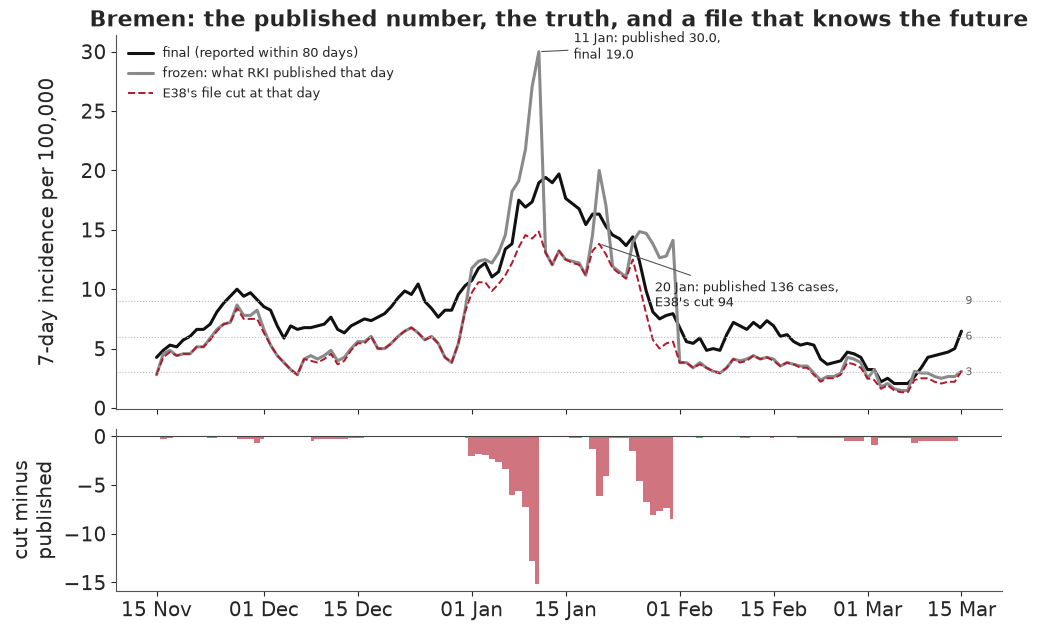

In [4]:
window = (DATES >= np.datetime64("2021-11-15")) & (DATES <= np.datetime64("2022-03-15"))
inc = lambda x: x * 1e5 / POP[hb]
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True, height_ratios=(3, 1.3))
top.plot(DATES[window], final[hb, window], color=FINAL, lw=2.2, label="final (reported within 80 days)")
top.plot(DATES[window], frozen[hb, window], color=FROZEN, lw=2.2, label="frozen: what RKI published that day")
top.plot(DATES[window], inc(cut[hb, window]), color=RKI, lw=1.4, ls="--", label="E38's file cut at that day")
for tau in TAUS:
    top.axhline(tau, color=MUTED, lw=0.8, ls=":")
    top.text(DATES[window][-1], tau, f" {tau}", va="center", fontsize=8, color="#666666")
jan11 = int(np.flatnonzero(DATES == np.datetime64("2022-01-11"))[0])
top.annotate(f"11 Jan: published {frozen[hb, jan11]:.1f},\nfinal {final[hb, jan11]:.1f}",
             (DATES[jan11], frozen[hb, jan11]), xytext=(25, -5), textcoords="offset points", fontsize=9,
             arrowprops=dict(arrowstyle="-", color="#555555", lw=0.8))
top.annotate(f"20 Jan: published {published[hb, jan20]:.0f} cases,\nE38's cut {cut[hb, jan20]:.0f}",
             (DATES[jan20], inc(cut[hb, jan20])), xytext=(40, -45), textcoords="offset points", fontsize=9,
             arrowprops=dict(arrowstyle="-", color="#555555", lw=0.8))
top.set(ylabel="7-day incidence per 100,000", title="Bremen: the published number, the truth, and a file "
        "that knows the future")
top.legend(loc="upper left", fontsize=9, frameon=False)
bottom.fill_between(DATES[window], 0, inc(gap[hb, window]), where=gap[hb, window] < 0, color=RKI, alpha=0.6,
                    step="mid", lw=0)
bottom.fill_between(DATES[window], 0, inc(gap[hb, window]), where=gap[hb, window] > 0, color=MODEL, alpha=0.6,
                    step="mid", lw=0)
bottom.axhline(0, color="#444444", lw=0.8)
bottom.set(ylabel="cut minus\npublished")
bottom.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.align_ylabels();

## 2 · How wrong was the first number, and what does a simple fix buy?

The ratio of final to frozen says how much a published week would still grow. The heatmap shows its median
by state and month, with the colour centred on the median over all state-days and states ordered by their
own median.

Median final/frozen over all 3,632 state-days: 1.83
By state: lowest Bremen 1.37, highest Hamburg 2.52
Share of state-days with final at least 1.5x frozen: 86%; with final below frozen: 0.6%


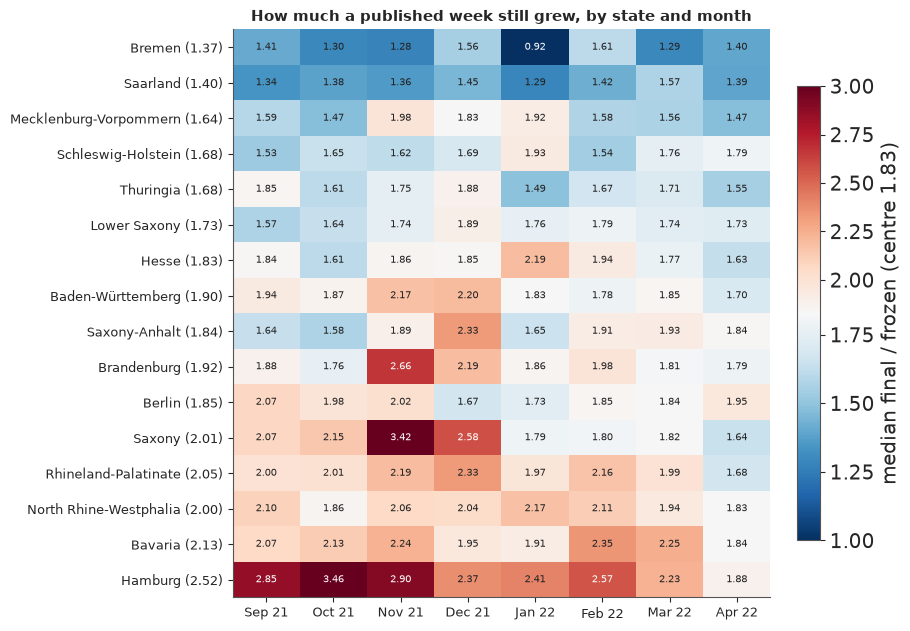

In [5]:
months = pd.PeriodIndex(pd.to_datetime(DATES), freq="M")
ratio = final / frozen
by_month = pd.DataFrame(ratio.T, columns=STATES).groupby(months).median().T
order = by_month.median(axis=1).sort_values().index
whole = float(np.median(ratio))
state_median = pd.Series(np.median(ratio, axis=1), index=STATES)
print(f"Median final/frozen over all {ratio.size:,} state-days: {whole:.2f}")
print(f"By state: lowest {NAMES[state_median.idxmin()]} {state_median.min():.2f}, highest "
      f"{NAMES[state_median.idxmax()]} {state_median.max():.2f}")
print(f"Share of state-days with final at least 1.5x frozen: {(ratio >= 1.5).mean():.0%}; "
      f"with final below frozen: {(ratio < 1).mean():.1%}")

fig, ax = plt.subplots(figsize=(9, 6.2))
image = ax.imshow(by_month.loc[order].to_numpy(), cmap="RdBu_r", aspect="auto",
                  norm=TwoSlopeNorm(vcenter=whole, vmin=1.0, vmax=3.0))
ax.set_yticks(range(len(order)), [f"{NAMES[s]} ({state_median[s]:.2f})" for s in order], fontsize=9)
ax.set_xticks(range(by_month.shape[1]), [m.strftime("%b %y") for m in by_month.columns], fontsize=9)
for i, s in enumerate(order):
    for j, value in enumerate(by_month.loc[s]):
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(value - whole) > 0.6 else "#222222")
fig.colorbar(image, ax=ax, label=f"median final / frozen (centre {whole:.2f})", shrink=0.8)
ax.set_title("How much a published week still grew, by state and month", fontsize=11)
ax.grid(False);

The bias was large: over all state-days a published week still grew by a median of 83%, and the state
medians run from 1.37 in Bremen to 2.52 in Hamburg. Within most states it moved by a few tenths from month
to month, with exceptions such as Saxony in November and Bremen in January, when its published values ran
above the final ones. A bias this stable is the case for the simplest fix. Four rules need no sampler,
and all of them use only what was known on the day:

- **Frozen**: the published value.
- **Revised, 7 days stale**: the value for the week ending 7 days ago, as known today. It has grown a week
  closer to final but describes an older week.
- **Factor**: frozen times the median ratio of the value reported within 40 days to the published one,
  over the last 28 dates complete at 40 days. Its ratio is always at least 40 days old, and it leaves out
  the cases reported at delays 41-80, between 0.5% (Bremen) and 5.7% (Hamburg) of the final count.
- **Ladder**: chain-ladder development factors from the last 42 rows, the actuaries' method.

They are scored on all 3,632 state-days by the mean absolute log error (0.1 is about 10% off), by the
mean absolute error in incidence (which is what CRPS becomes for a single number), and by false alarms (FP:
signal at or above $\tau$, final below) and misses (FN) at each threshold, counted in state-days.

In [6]:
LABEL = {"frozen": "Frozen", "revised_7d_stale": "Revised, 7 days stale", "factor": "Factor", "ladder": "Ladder",
         "model": "**PyMC nowcast**"}


def bar_table(names):
    rows = []
    for name in names:
        row = scores["signals"][name]
        rows.append([LABEL[name], f"{row['mae_log']:.3f}", f"{row['crps']:.2f}",
                     *[f"{row[f'tau{t}'][0]:,} / {row[f'tau{t}'][1]:,}" for t in TAUS]])
    return pd.DataFrame(rows, columns=["Signal", "MAE log", "CRPS", "tau 3 FP / FN", "tau 6 FP / FN",
                                       "tau 9 FP / FN"])


display(markdown_table(bar_table(("frozen", "revised_7d_stale", "factor", "ladder"))))
print(f"State-days scored: {scores['state_days']:,}; true crossings (final at or above tau for 3 days after "
      f"3 below): {', '.join(f'tau {t}: {n}' for t, n in decision['crossings'].items())}")

| Signal | MAE log | CRPS | tau 3 FP / FN | tau 6 FP / FN | tau 9 FP / FN |
|---|---|---|---|---|---|
| Frozen | 0.619 | 4.32 | 1 / 742 | 0 / 1,262 | 4 / 1,174 |
| Revised, 7 days stale | 0.289 | 2.31 | 23 / 228 | 75 / 552 | 42 / 503 |
| Factor | 0.155 | 1.43 | 49 / 66 | 153 / 113 | 180 / 151 |
| Ladder | 0.168 | 1.54 | 61 / 66 | 137 / 191 | 129 / 204 |

State-days scored: 3,632; true crossings (final at or above tau for 3 days after 3 below): tau 3: 17, tau 6: 35, tau 9: 29


The frozen value missed 1,262 state-days above 6 and almost never raised a false alarm: it was a late,
timid signal. The factor cuts its log error from 0.62 to 0.155 and its misses at $\tau = 6$ from 1,262 to
113, at the price of 153 false alarms. The ladder does no better than the factor. So the standard a model
must meet, set before the run, is the factor, and it is a high one: a constant correction already gets most of the way. A model can
earn its place only through what the factor cannot give, a probability that means what it says and an
alert rule tuned to a stated false-alarm rate, and by doing better where the factor's ratio goes stale,
as in Bremen's revisions or over Christmas.

## 3 · The model

The model nowcasts all 16 states jointly on each as-of date, from a 70-day window of the triangle as it was
known that day. Let $n_{s,t,b}$ be the cases of state $s$ with Meldedatum $t$ whose hospitalisation arrived
in delay bin $b$ (days 0-14 one by one, then 15-21, 22-28 and 29-42: 18 bins). A bin enters only if all its
days are known on the as-of date. Then

$$n_{s,t,b} \sim \operatorname{NegBinomial}\bigl(\lambda_{s,t}\, p_{s,t,b},\ \phi_s\bigr),$$

with an expected total $\lambda$ and delay probabilities $p$ built from a discrete hazard
$h_{s,t,b}$, the chance that a case not yet reported arrives in bin $b$:

$$p_{s,t,b} = h_{s,t,b} \prod_{c < b} (1 - h_{s,t,c}), \qquad
\operatorname{logit} h_{s,t,b} = \gamma_b + \gamma^{s}_{b} + \rho_{s,\,\mathrm{wd}(t+b)}
+ \beta_{w(t)} + \beta^{s}_{w(t)}.$$

Here $\gamma_b$ is a random walk over delay, $\gamma^s_b$ a state offset made of three smooth basis
functions, $\rho$ a reporting-weekday effect for the daily bins, and $\beta$ weekly national and state
drift in reporting speed. The level is an integrated growth path, $\log \lambda_{s,t} = \ell_{s,0} +
\sum_{u \le t} g_{s,w(u)} + \omega_{s,\mathrm{wd}(t)}$, with weekly growth $g$ made of a national random
walk plus partially pooled state deviations and a Meldedatum weekday effect $\omega$. Cases reported
after day 42 are outside the window, so the final total is scaled by a tail ratio per state, the share of
cases at delay 43-80 among rows already complete on the as-of date, drawn from a Gamma.

Before the code, the choices that shaped it:

| Decision | Choice | Why | What it costs |
|---|---|---|---|
| Data | Vintages rebuilt from the unprocessed triangle | E38's file knows the future (section 1) | A rebuild and 16 snapshot checks |
| Target | Final 7-day incidence within 80 days | The threshold read as burden; the hub scored the same | Not the legal reading (the objection above) |
| Unit | 16 states in one model, all ages | Thresholds act on all-age state values; states share growth and delay | 621 parameters, 17,024 cells per fit |
| Delay bins | 18, daily to 14 days, then 3 wide bins to 42 | Late cells are few and noisy | Detail beyond day 14 |
| Tail beyond 42 days | A Gamma ratio from complete rows | 1-6% of cases; a 70-day window cannot see them | Ignores drift in the tail |
| Likelihood | Negative binomial, one dispersion per state | Counts are overdispersed | Cell-level only (section 6) |
| Scales | LogNormal priors, non-centred walks | E86's lesson on heavy tails in hierarchical scales | Priors had to be tightened (below) |
| Refit | Daily full fit, no daily update | The cheap update failed its test (section 4) | 227 fits instead of 38 |
| Sampler | ChEES, 32 chains, float32 on a GPU | About 5 times the passing fits per hour of nutpie on the CPU in float64 (section 4) | A GPU, and precision checks |
| Holidays | None | Not planned | The model's worst stretch is Christmas (section 5) |

The cell below builds the model on three states, Bavaria (a large state), Bremen (the revision shocks) and
Hamburg (the slowest reporter), on 13 January 2022, the hardest date of the pilots. A reader has no
unprocessed triangle, so the window is cut from E38's file; section 1 showed that this is close for
Bavaria and Hamburg and not for Bremen, which is fine for building the model and its prior, not for
fitting it. The function is the one the stored run used (`tools/e90_core.py`), shortened to the honest
variant.

In [7]:
T, K, B = 70, 7, 18
N_HAZARD = B - 1
BIN_EDGES = [(d, d) for d in range(15)] + [(15, 21), (22, 28), (29, 42)]
BIN_LAST = np.array([hi for _, hi in BIN_EDGES])
KNOWN = BIN_LAST[None, :] <= (T - 1 - np.arange(T))[:, None]  # (T, B): whole bins only, the same every day
FUTURE = BIN_LAST[None, :] > (K - 1 - np.arange(K))[:, None]  # (K, B): bins of the last week still to come
THREE = ("DE-BY", "DE-HB", "DE-HH")
MAIN = np.datetime64("2022-01-13")


def window_from_e38(asof, states=THREE):
    """One as-of window cut from E38's file: binned counts, the last week's known cases, tail, weekdays."""
    a = int((asof - FIRST_ROW).astype(int))
    rows = np.arange(a - T + 1, a + 1)
    y, kept7, tail = [], [], []
    for state in states:
        block = e38[STATES.index(state)]
        cells = block[rows] * (np.arange(81)[None, :] <= (a - rows)[:, None])
        y.append(np.stack([np.where(KNOWN[:, k], cells[:, lo : hi + 1].sum(1), -1)
                           for k, (lo, hi) in enumerate(BIN_EDGES)], axis=1))
        kept7.append(cells[-K:].sum(1))
        old = block[a - 80 - 27 : a - 80 + 1]  # the last 28 rows complete at 80 days
        inside, beyond = old[:, :43].sum(), old[:, 43:].sum()
        tail.append(((beyond + 0.5) / inside, beyond + 0.5, inside))
    dow = ((FIRST_ROW + rows).astype("int64") + 3) % 7  # Monday = 0
    y = np.stack(y)
    return {"states": states, "y": y.astype(np.int64), "kept7": np.stack(kept7), "tail": np.array(tail),
            "dow": dow, "rep": (dow[:, None] + np.arange(N_HAZARD)) % 7,
            "l0_mu": np.log(np.maximum(y[:, :7].sum(2).mean(1), 1.0)),
            "population": POP[[STATES.index(s) for s in states]]}


def build_model(d):
    """Section 3's nowcast: centred likelihood, non-centred walks, LogNormal scales."""
    S, rows = len(d["states"]), T
    weeks = (rows - 1) // 7 + 1
    ti, bi = np.nonzero(KNOWN)
    si = np.repeat(np.arange(S), ti.size)
    flat = np.ravel_multi_index((si, np.tile(ti, S), np.tile(bi, S)), (S, rows, B))
    week = np.arange(rows) // 7
    basis = np.stack([np.cos(np.pi * k * (np.arange(N_HAZARD) + 0.5) / N_HAZARD) for k in range(3)], 1)
    basis = basis / np.linalg.norm(basis, axis=0)
    daily = (np.arange(N_HAZARD) < 15).astype(float)
    coords = {"state": list(d["states"]), "weekday": list(range(7)), "basis": [0, 1, 2]}

    def walk(name, shape, sigma):
        steps = sigma * pm.Normal(name, 0.0, 1.0, shape=shape)
        return pt.concatenate([pt.zeros((*shape[:-1], 1)), pt.cumsum(steps, axis=-1)], axis=-1)

    with pm.Model(coords=coords) as model:
        y = pm.Data("y", d["y"][:, KNOWN].ravel())
        dow, rep, l0_mu = pm.Data("dow", d["dow"]), pm.Data("rep", d["rep"]), pm.Data("l0_mu", d["l0_mu"])
        # level: integrated weekly growth, a national walk plus partially pooled state deviations
        l0 = l0_mu + 0.5 * pm.Normal("l0_z", 0.0, 1.0, shape=S)
        g0 = pm.Normal("g0", 0.0, 0.02)
        s_nat = pm.LogNormal("s_nat", np.log(0.015), 0.5)
        s_dev = pm.LogNormal("s_dev", np.log(0.007), 0.5)
        s_dev0 = pm.LogNormal("s_dev0", np.log(0.01), 0.5)
        g_nat = g0 + walk("g_nat", (weeks - 1,), s_nat)
        g_dev = (s_dev0 * pm.Normal("g_dev0_z", 0.0, 1.0, shape=S))[:, None] + walk("g_dev", (S, weeks - 1), s_dev)
        daily_growth = (g_nat[None, :] + g_dev)[:, week]
        level = l0[:, None] + pt.concatenate([pt.zeros((S, 1)), pt.cumsum(daily_growth[:, 1:], axis=1)], axis=1)
        wd = pm.ZeroSumNormal("wd", sigma=0.5, dims=("state", "weekday"), n_zerosum_axes=1)
        log_lam = level + wd[:, dow]
        # hazard: a delay walk, low-rank state offsets, reporting weekday, weekly drift
        gamma0 = pm.Normal("gamma0", -1.3, 1.0)
        s_gamma = pm.LogNormal("s_gamma", np.log(0.3), 0.7)
        gamma = gamma0 + s_gamma * pt.concatenate([pt.zeros(1), pt.cumsum(pm.Normal("gamma_z", 0.0, 1.0,
                                                                                    shape=N_HAZARD - 1))])
        s_a = pm.LogNormal("s_a", np.log(0.3), 0.7, dims="basis")
        gamma_s = pt.dot(s_a[None, :] * pm.Normal("a_z", 0.0, 1.0, dims=("state", "basis")), basis.T)
        rho = pm.ZeroSumNormal("rho", sigma=1.0, dims=("state", "weekday"), n_zerosum_axes=1)
        beta = walk("beta", (weeks - 1,), pm.LogNormal("s_beta", np.log(0.07), 0.7))
        beta_s = walk("beta_s", (S, weeks - 1), pm.LogNormal("s_beta_s", np.log(0.05), 0.7))
        logit_h = (gamma[None, None, :] + gamma_s[:, None, :] + rho[:, rep] * daily[None, None, :]
                   + (beta[None, :] + beta_s)[:, week][:, :, None])
        log_h, log_1mh = -pt.softplus(-logit_h), -pt.softplus(logit_h)
        log_p = (pt.concatenate([log_h, pt.zeros((S, rows, 1))], axis=2)  # the last column: still to come
                 + pt.concatenate([pt.zeros((S, rows, 1)), pt.cumsum(log_1mh, axis=2)], axis=2))
        log_mu = log_lam[:, :, None] + log_p
        phi = pm.Deterministic("phi", 1 / pm.LogNormal("inv_sqrt_phi", np.log(0.25), 0.5, shape=S) ** 2)
        pm.NegativeBinomial("n", mu=pt.exp(log_mu.ravel()[flat]), alpha=phi[si], observed=y)
        pm.Deterministic("mu7", pt.exp(log_mu[:, -K:, :]))
    return model


three = window_from_e38(MAIN)
model = build_model(three)
size = sum(np.size(v) for v in model.initial_point().values())
print(f"Three states on {MAIN}: {int((three['y'] >= 0).sum()):,} cells, {size} parameters; known cases in "
      f"the last 7 days {', '.join(f'{s} {k:.0f}' for s, k in zip(THREE, three['kept7'].sum(1)))}; tail ratio "
      f"{', '.join(f'{r:.3f}' for r in three['tail'][:, 0])}")
print("Free variables and their shapes:", ", ".join(f"{v.name} {tuple(point[v.name].shape)}"
                                                    for v in model.value_vars for point in [model.initial_point()]))

Three states on 2022-01-13: 3,192 cells, 153 parameters; known cases in the last 7 days DE-BY 331, DE-HB 82, DE-HH 102; tail ratio 0.010, 0.017, 0.041


Free variables and their shapes: l0_z (3,), g0 (), s_nat_log__ (), s_dev_log__ (), s_dev0_log__ (), g_nat (9,), g_dev0_z (3,), g_dev (3, 9), wd_zerosum__ (3, 6), gamma0 (), s_gamma_log__ (), gamma_z (16,), s_a_log__ (3,), a_z (3, 3), rho_zerosum__ (3, 6), s_beta_log__ (), beta (9,), s_beta_s_log__ (), beta_s (3, 9), inv_sqrt_phi_log__ (3,)


### The prior predictive, and a check that could never pass

Before any fit, the check set for the prior asked that its 95% interval for the final 7-day total contain
both 0.1 and 10 times the observed final value: wide enough not to decide the answer, narrow enough not to be
absurd. A final total is the known cases of the last week plus the cases still to come, all times the
tail, so we draw the level and delays from the prior and the cells still to come from the negative
binomial.

 Bavaria: final   602, known  331; prior 95% of the final total    335 to   319,333 (530x final). Contains 0.1x? False; 10x? True
  Bremen: final   129, known   82; prior 95% of the final total     82 to     4,380 (34x final). Contains 0.1x? False; 10x? True
 Hamburg: final   227, known  102; prior 95% of the final total    105 to    19,240 (85x final). Contains 0.1x? False; 10x? True
Stored run, true vintage: 97.5% at 764x, 32x, 94x final; 0.1x contained: [False, False, False]


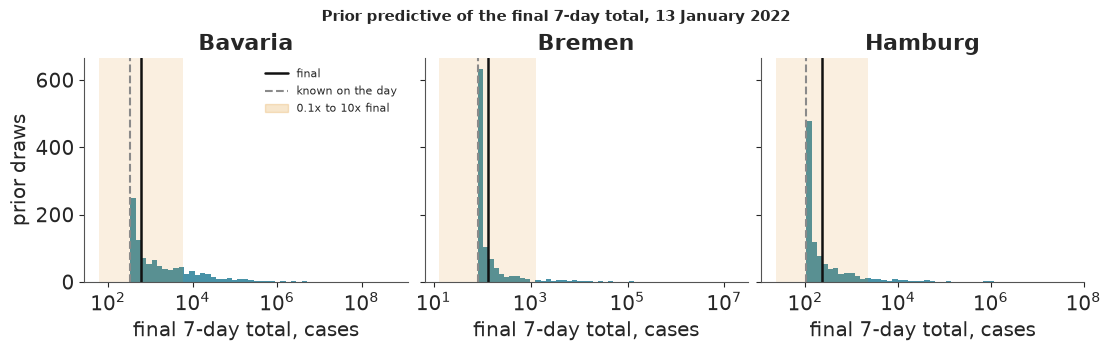

In [8]:
with model:
    prior = pm.sample_prior_predictive(1000, var_names=["mu7", "phi"], random_seed=RANDOM_SEED)
mu7 = prior.prior["mu7"].values.reshape(-1, 3, K, B)
phi = prior.prior["phi"].values.reshape(-1, 3)
still_to_come = rng.poisson(rng.gamma(phi[:, :, None, None] * np.ones_like(mu7), mu7 / phi[:, :, None, None]))
tail = 1 + rng.gamma(three["tail"][:, 1], 1 / three["tail"][:, 2], size=phi.shape)
prior_total = (three["kept7"].sum(1) + (still_to_come * FUTURE).sum((2, 3))) * tail
expected_new = (mu7 * FUTURE).sum((2, 3)) * tail
truth3 = final[[STATES.index(s) for s in THREE], np.flatnonzero(DATES == MAIN)[0]] * three["population"] / 1e5
low, high = np.quantile(prior_total, [0.025, 0.975], axis=0)
for i, s in enumerate(THREE):
    print(f"{NAMES[s]:>8}: final {truth3[i]:5.0f}, known {three['kept7'][i].sum():4.0f}; prior 95% of the final "
          f"total {low[i]:6.0f} to {high[i]:9,.0f} ({high[i] / truth3[i]:.0f}x final). Contains 0.1x? "
          f"{low[i] <= 0.1 * truth3[i]}; 10x? {high[i] >= 10 * truth3[i]}")
print(f"Stored run, true vintage: 97.5% at {', '.join(f'{h / f:.0f}x' for h, f in zip(pilots['p3_cpu']['prior_high'], pilots['p3_cpu']['final']))} final; "
      f"0.1x contained: {pilots['p3_cpu']['covers']}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for i, (ax, s) in enumerate(zip(axes, THREE)):
    edges = np.logspace(np.log10(max(prior_total[:, i].min(), 1)), np.log10(prior_total[:, i].max()), 50)
    ax.hist(prior_total[:, i], bins=edges, color=MODEL, alpha=0.75)
    ax.axvspan(0.1 * truth3[i], 10 * truth3[i], color=FACTOR, alpha=0.12, lw=0)
    ax.axvline(truth3[i], color=FINAL, lw=1.8)
    ax.axvline(three["kept7"][i].sum(), color=FROZEN, lw=1.5, ls="--")
    ax.set(xscale="log", title=NAMES[s], xlabel="final 7-day total, cases")
axes[0].set_ylabel("prior draws")
axes[0].legend(handles=[Line2D([], [], color=FINAL, lw=1.8, label="final"),
                        Line2D([], [], color=FROZEN, ls="--", label="known on the day"),
                        plt.Rectangle((0, 0), 1, 1, color=FACTOR, alpha=0.2, label="0.1x to 10x final")],
               fontsize=8, frameon=False, loc="upper right")
fig.suptitle("Prior predictive of the final 7-day total, 13 January 2022", fontsize=11);

The upper end is generous, 34 to 530 times the final value here (764 times for Bavaria on the true
vintage), and the first draft of these priors had reached $10^8$ cases before its scales were tightened.
The lower end can never pass: the prior total cannot fall below the cases already known, and those are
well above a tenth of the final value. The check was badly written, not the prior, and it stays failed as
written. A check of the *expected* number
of cases still to come covers both ends, and that is the check the run relied on, labelled as added later:

In [9]:
lo_e, hi_e = np.quantile(expected_new, [0.025, 0.975], axis=0)
for i, s in enumerate(THREE):
    still = truth3[i] - three["kept7"][i].sum()
    print(f"{NAMES[s]:>8}: cases still to come in truth {still:5.0f}; prior 95% of the expected {lo_e[i]:7.1f} to "
          f"{hi_e[i]:9,.0f}: contains 0.1x and 10x? {lo_e[i] <= 0.1 * still and hi_e[i] >= 10 * still}")

 Bavaria: cases still to come in truth   271; prior 95% of the expected     0.6 to   309,594: contains 0.1x and 10x? True
  Bremen: cases still to come in truth    47; prior 95% of the expected     0.0 to     4,657: contains 0.1x and 10x? True
 Hamburg: cases still to come in truth   125; prior 95% of the expected     0.1 to    18,931: contains 0.1x and 10x? True


### What one gradient costs

A gradient-based sampler spends almost all its time in the gradient of the log density, so its cost is
the first thing to measure (E87). Here it is on this machine's CPU, for three states.

In [10]:
dlogp = model.logp_dlogp_function(ravel_inputs=True)
dlogp.set_extra_values({})
point = model.initial_point()
q0 = np.concatenate([np.ravel(point[v.name]) for v in model.value_vars])
dlogp._pytensor_function(q0)
times = []
for _ in range(200):
    x = q0 + 0.05 * rng.normal(size=q0.size)
    t0 = time.perf_counter()
    dlogp._pytensor_function(x)
    times.append(time.perf_counter() - t0)
print(f"Gradient, three states, {q0.size} parameters, one thread here ({pytensor.config.linker} linker): "
      f"median {1000 * np.median(times):.2f} ms")
print(f"Stored run, same model on the true vintage: {pilots['p3_cpu']['gradient_ms_median']:.2f} ms on one core "
      f"(numba); 16 states on the GPU, 32 chains at once: 0.60 ms in float32, 3.31 ms in float64")
del prior, mu7, still_to_come

Gradient, three states, 153 parameters, one thread here (auto linker): median 0.75 ms
Stored run, same model on the true vintage: 0.74 ms on one core (numba); 16 states on the GPU, 32 chains at once: 0.60 ms in float32, 3.31 ms in float64


A gradient of the three-state model takes under a millisecond here, the same as in the stored run. On the
GPU the 16-state model runs 32 chains at once in 0.60 ms per step in float32, and 5.5 times slower in
float64, which is why the run used float32 and checked what it costs.

## 4 · What 227 fits cost, and does the GPU earn its place?

Sixteen states make 17,024 cells and 621 parameters per fit. It is not obvious that a GPU helps a model this
size, and the honest test is the same model on the same dates against the best CPU set-up rather than a
crippled one. The CPU route is nutpie in float64, 4 chains per fit,
three fits at once on 12 threads; it needed `target_accept=0.95` to keep divergences under 0.1%. The GPU
route is ChEES (Hoffman, Radul & Sountsov 2021) with 32 chains in float32, a two-stage warm-up that culls
stuck chains (E86), and `target_accept=0.85`. Both were judged on the bulk ESS of the 16 final 7-day
totals, the quantities the decision uses.

In [11]:
p5 = pilots["p5_eval"]
pilot_rows = pd.DataFrame([[r["date"], f"{r['gpu_wall_s']:.0f}", f"{r['gpu_ess']:,.0f}", f"{r['gpu_div']:.3%}",
                            f"{r['cpu_wall_s']:,.0f}", f"{r['cpu_ess']:,.0f}", f"{r['cpu_div']:.3%}",
                            f"{r['z_max']:.2f}", f"{r['dp_max']:.3f}"] for r in p5["rows"]],
                          columns=["as-of", "GPU wall, s", "GPU ESS", "GPU div.", "CPU wall, s", "CPU ESS",
                                   "CPU div.", "largest |z|", "largest P gap"])
display(markdown_table(pilot_rows))
print(f"ESS per second over the 6 dates: GPU {p5['gpu_ess_per_s']:.0f} for the whole fit "
      f"({p5['gpu_sampling_only_ess_per_s']:.0f} sampling only); CPU pool {p5['pool_ess_per_s']:.2f} "
      f"({p5['pool_wall_s']:,.0f} s for both rounds of 3 fits). GPU / pool = {p5['ratio']:.0f}x, or "
      f"{p5['ratio_15_cores']:.0f}x against all 15 cores (extrapolated)")
gpu_per_fit = np.mean([r["gpu_wall_s"] for r in p5["rows"]])
pool_per_fit = p5["pool_wall_s"] / len(p5["rows"])
print(f"Wall time per passing fit: GPU {gpu_per_fit:.0f} s, CPU pool {pool_per_fit:,.0f} s (3 at a time) = "
      f"{pool_per_fit / gpu_per_fit:.1f}x the fits per hour on the GPU; draws per fit 32,000 against 4,000")
print(f"Do the routes agree? Largest |z| of the 16 totals {p5['route_z_max']:.2f}, largest gap in P(cross) "
      f"{p5['route_dp_max']:.3f}")
print(f"Float32 against float64 log density: sd of the difference {pilots['p3_precision']['sd']:.3f} nats "
      f"over {pilots['p3_precision']['n']} draws (line 0.1)")

| as-of | GPU wall, s | GPU ESS | GPU div. | CPU wall, s | CPU ESS | CPU div. | largest |z| | largest P gap |
|---|---|---|---|---|---|---|---|---|
| 2022-01-13 | 266 | 31,610 | 0.016% | 3,363 | 4,038 | 0.025% | 1.80 | 0.008 |
| 2021-10-03 | 226 | 27,055 | 0.019% | 2,761 | 1,762 | 0.000% | 1.74 | 0.010 |
| 2021-11-14 | 257 | 30,573 | 0.044% | 2,128 | 3,889 | 0.000% | 1.93 | 0.009 |
| 2021-12-26 | 273 | 26,956 | 0.106% | 2,462 | 2,904 | 0.000% | 1.89 | 0.011 |
| 2022-02-18 | 298 | 30,264 | 0.041% | 4,831 | 3,765 | 0.000% | 2.07 | 0.010 |
| 2022-04-01 | 264 | 31,248 | 0.034% | 4,888 | 3,733 | 0.050% | 3.00 | 0.013 |

ESS per second over the 6 dates: GPU 112 for the whole fit (215 sampling only); CPU pool 2.43 (8,266 s for both rounds of 3 fits). GPU / pool = 46x, or 37x against all 15 cores (extrapolated)
Wall time per passing fit: GPU 264 s, CPU pool 1,378 s (3 at a time) = 5.2x the fits per hour on the GPU; draws per fit 32,000 against 4,000
Do the routes agree? Largest |z| of the 16 totals 3.00, largest gap in P(cross) 0.013
Float32 against float64 log density: sd of the difference 0.013 nats over 800 draws (line 0.1)


By ESS per second the GPU wins by a factor of 46, but that number mostly counts draws. Both routes give an
ESS close to the number of draws they were asked for, 27,000-31,600 of 32,000 on the GPU and 1,760-4,040
of 4,000 under nutpie, so the ratio is largely the 8 times as many chains. Both cleared the 400 line on
every date, and what the run needs is fits that pass, so the fairer number is wall time per fit: 264 s
against 1,378 s in the pool, about 5 times as many fits per hour. That is still the difference between
17 hours and 3.6 days for the 227 fits, and the GPU earns its place. The comparison also mixes precision:
the GPU ran float32 and nutpie float64, the GPU's own float64 gradient is 5.5 times slower, and nutpie in
float32 was not tried, so at equal precision the gap could be much smaller; that was not measured. Timings
were not isolated either (GPU fits ran beside the CPU pool). The two routes agree: the largest of the 96 z-scores (16 totals on 6 dates) is 3.00,
at the pilot's line of 3, and no alert probability differs by more than 0.013. Float32 costs 0.013 nats of log density,
far below anything that moves a decision.

**The daily update that failed.** A cheaper design was tried first: fit every sixth day and, between fits, update each
posterior draw with the new day's reports in closed form, keeping the delay parameters fixed. The pilot
compared that update with full fits five days on, and the gap in $P(\text{final} \ge \tau)$ was 0 at the
median but up to 0.94, over 0.10 for 15% of comparisons. A control with no gap at all gave a maximum of
0.34, so the update is an approximation, not a bug, and it failed worst from 26 December and in mid-November,
when reporting was changing fast. A two-day gap still failed (largest gap 0.99). So the run fitted every day.

In [12]:
p6 = pilots["p6"]
print(f"Update after 5 days against a full fit: median gap {p6['median_abs']:.2f}, largest {p6['max_abs']:.2f}, "
      f"share over 0.10 {p6['share_over_0.10']:.1%} of {p6['n']} (lines 0.03 and 0.10)")
print(f"Gap 0 control: largest {pilots['p6_control']['max']:.2f}; gap 2: largest {pilots['p6_gap2']['max_abs']:.2f}, "
      f"over 0.10 {pilots['p6_gap2']['share_over_0.10']:.1%}")
for row in p6["rows"]:
    print(f"  from {row['from']} to {row['to']}: largest gap {row['max']:.2f}")

Update after 5 days against a full fit: median gap 0.00, largest 0.94, share over 0.10 14.6% of 240 (lines 0.03 and 0.10)
Gap 0 control: largest 0.34; gap 2: largest 0.99, over 0.10 8.8%
  from 2021-10-03 to 2021-10-08: largest gap 0.27
  from 2021-11-14 to 2021-11-19: largest gap 0.93
  from 2021-12-26 to 2021-12-31: largest gap 0.94
  from 2022-02-18 to 2022-02-23: largest gap 0.51
  from 2022-04-01 to 2022-04-06: largest gap 0.37


### Every fit, checked

One bad fit among 227 can hide in an average, so every fit had to pass three lines on the 16 totals:
$\hat R \le 1.01$, bulk ESS at least 400 and divergences at most 0.1% of transitions. A fit that failed
was kept, restarted once with a new seed, and the restart had to pass.

In [13]:
fit_frame = pd.DataFrame({"date": DATES, "wall": [f["wall_s"] for f in fits], "r_hat": [f["gate"]["r_hat"] for f in fits],
                          "ess": [f["gate"]["ess"] for f in fits], "div": [f["gate"]["divergence"] for f in fits],
                          "restart": [f["attempt"] == 1 for f in fits]})
failed = {name[len("failed_gpu_fits_"):]: store.load_json(name) for name in run["failed_runs"]}
sf = run["state_fits"]
print(f"{sf['n']} fits, all passing: worst r_hat {sf['r_hat_max']:.4f}, smallest ESS {sf['ess_min']:,.0f}, most "
      f"divergences {sf['divergence_max']:.3%}; wall mean {sf['wall_s_mean']:.0f} s, longest {sf['wall_s_max']:.0f} s, "
      f"{sf['wall_s_total'] / 3600:.1f} h in all")
print(f"{len(failed)} dates passed only on the restart:")
for date, f in failed.items():
    gate = (f"r_hat {f['gate']['r_hat']:6.2f}, ESS {f['gate']['ess']:7,.0f}" if "gate" in f
            else "r_hat and ESS not in its record (a pilot fit)")
    print(f"  {date}: {gate}, divergences {f['divergence_rate']:.2%}, step size {f['step_size']:.1e}")
print(f"Chains culled as stuck in warm-up: {sf['stuck_chains']}; flagged for a possible minor mode and not "
      f"inspected: {sf['check_mode_chains']}")

227 fits, all passing: worst r_hat 1.0018, smallest ESS 19,788, most divergences 0.100%; wall mean 266 s, longest 408 s, 16.7 h in all
12 dates passed only on the restart:
  2021-11-05: r_hat   1.00, ESS  29,364, divergences 0.12%, step size 1.1e-02
  2021-11-08: r_hat   1.06, ESS   4,698, divergences 3.12%, step size 9.7e-03
  2021-12-26: r_hat and ESS not in its record (a pilot fit), divergences 0.11%, step size 9.1e-03
  2022-01-12: r_hat   1.03, ESS   7,587, divergences 1.30%, step size 1.2e-02
  2022-01-21: r_hat   1.04, ESS     556, divergences 1.46%, step size 1.1e-02
  2022-01-27: r_hat   1.08, ESS     735, divergences 2.65%, step size 1.1e-02
  2022-02-01: r_hat   1.00, ESS  28,639, divergences 0.14%, step size 1.0e-02
  2022-02-02: r_hat   1.00, ESS  28,944, divergences 0.12%, step size 1.0e-02
  2022-02-03: r_hat   1.00, ESS  29,687, divergences 0.13%, step size 9.4e-03
  2022-02-16: r_hat  13.80, ESS      32, divergences 0.00%, step size 2.4e-07
  2022-03-22: r_hat   1.00, 

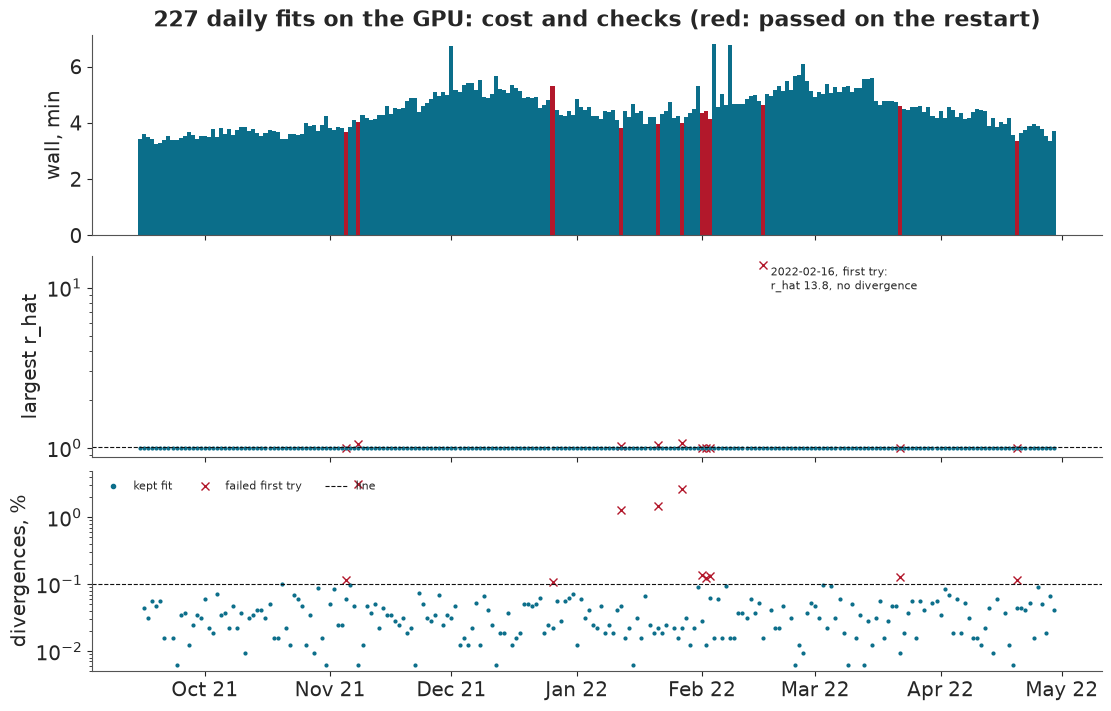

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].bar(fit_frame["date"], fit_frame["wall"] / 60, width=1.0, color=np.where(fit_frame["restart"], RKI, MODEL))
axes[0].set(ylabel="wall, min", title="227 daily fits on the GPU: cost and checks (red: passed on the restart)")
for date, f in failed.items():
    d = np.datetime64(date)
    if "gate" in f:
        axes[1].plot(d, f["gate"]["r_hat"], "x", color=RKI, ms=6)
    axes[2].plot(d, f["divergence_rate"] * 100, "x", color=RKI, ms=6)
axes[1].plot(fit_frame["date"], fit_frame["r_hat"], ".", color=MODEL, ms=4)
axes[1].axhline(1.01, color=FINAL, lw=0.8, ls="--")
axes[1].set(yscale="log", ylabel="largest r_hat")
axes[1].text(np.datetime64("2022-02-16"), 13.8, "  2022-02-16, first try:\n  r_hat 13.8, no divergence",
             fontsize=8, va="top")
axes[2].plot(fit_frame["date"], fit_frame["div"] * 100, ".", color=MODEL, ms=4)
axes[2].axhline(0.1, color=FINAL, lw=0.8, ls="--")
axes[2].set(yscale="log", ylabel="divergences, %", ylim=(0.005, 5))
axes[2].legend(handles=[Line2D([], [], marker=".", ls="", color=MODEL, label="kept fit"),
                        Line2D([], [], marker="x", ls="", color=RKI, label="failed first try"),
                        Line2D([], [], color=FINAL, ls="--", lw=0.8, label="line")], fontsize=8, ncol=3,
               frameon=False, loc="upper left")
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"));

Seven failures were just over the divergence line (0.11-0.14%), and four were plain failures with 1.3-3.1%
divergences and $\hat R$ of 1.03-1.08. The dangerous one was quiet. On 16 February 2022 the first fit
reported no divergences at all and a mean acceptance of 0.99, which looks perfect, but its step size had
collapsed to about $2 \times 10^{-7}$: the chains barely moved after warm-up and sat where warm-up left them.
$\hat R$ of 13.8 and a bulk ESS of 32 gave it away, and its record shows more warning signs: the
trajectory length sat at its cap of 1,000 steps, so each chain spent about 500,000 gradients going nowhere.
Divergences and acceptance alone looked perfect. The draws of the state with the widest spread between chains show it;
the scatter within each chain is the count noise drawn on top of each draw.

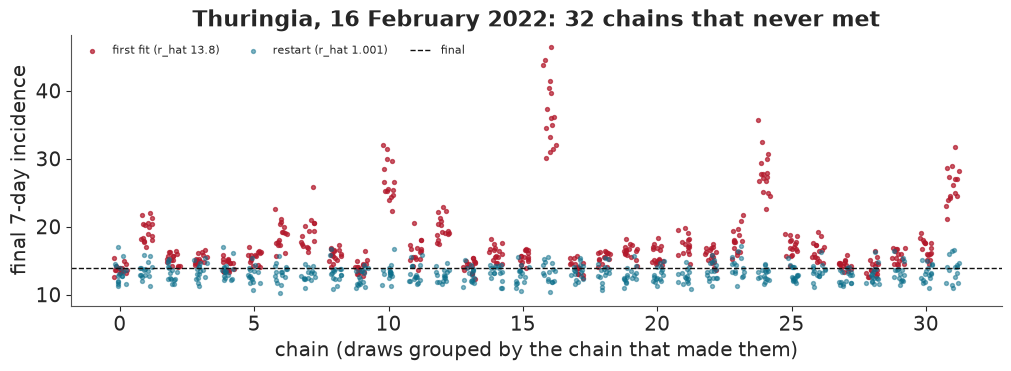

In [15]:
bad, good = pack["feb16_failed"].astype(float), pack["feb16_refit"].astype(float)
chain_of = np.arange(len(bad)) * (32000 // len(bad)) // 1000  # draws are stored chain by chain, thinned
spread = [np.ptp([np.median(bad[chain_of == c, s]) for c in range(32)]) for s in range(16)]
worst = int(np.argmax(spread))
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.scatter(chain_of + rng.uniform(-0.25, 0.25, len(bad)), bad[:, worst], s=8, color=RKI, alpha=0.7,
           label="first fit (r_hat 13.8)")
ax.scatter(chain_of + rng.uniform(-0.25, 0.25, len(good)), good[:, worst], s=8, color=MODEL, alpha=0.5,
           label="restart (r_hat 1.001)")
ax.axhline(final[worst, np.flatnonzero(DATES == np.datetime64("2022-02-16"))[0]], color=FINAL, lw=1, ls="--",
           label="final")
ax.set(xlabel="chain (draws grouped by the chain that made them)", ylabel="final 7-day incidence",
       title=f"{NAMES[STATES[worst]]}, 16 February 2022: 32 chains that never met")
ax.legend(fontsize=8, frameon=False, ncol=3, loc="upper left");

A check on the decision quantity caught it, and a check only on divergences would not have. The culling
step meant to replace stuck chains (E86) did act: its first pass found a chain 225 standard deviations from
the rest and replaced 5 stuck chains, its second 2 more. It did not catch the rest, because each of them
sat stably in its own place.
A milder version of the same failure, on a fit that just passes, would not be caught. 72 chains flagged as
possibly in a minor mode were never inspected one by one.

## 5 · Is the nowcast a better number?

Each fit gives 32,000 draws of the final 7-day incidence of every state; the median is the point
nowcast. The table of section 2 now has its fifth row. CRPS, the continuous ranked probability score, is the mean
absolute error of the whole predictive distribution, in incidence units: for a single number it reduces to
the absolute error, so the five rows compare directly.

In [16]:
display(markdown_table(bar_table(("frozen", "revised_7d_stale", "factor", "ladder", "model"))))
wins = scores["model_wins_dates"]
print(f"The model's log error is below the factor's on {wins} of {scores['dates_scored']} dates")
better_states = [s for s, v in scores["by_state_mae"].items() if v["model"] < v["factor"]]
print(f"... and in {len(better_states)} of 16 states; the factor is better in "
      f"{', '.join(NAMES[s] for s in STATES if s not in better_states)}")
for w, v in scores["by_wave_mae"].items():
    print(f"  {w:5}: model {v['model']:.3f}, factor {v['factor']:.3f}")
xmas = scores["christmas_dates_mae"]
print(f"Christmas ({xmas['dates']}): model {xmas['model']:.3f}, factor {xmas['factor']:.3f}, "
      f"80% coverage {xmas['cover']['80']:.2f}")

| Signal | MAE log | CRPS | tau 3 FP / FN | tau 6 FP / FN | tau 9 FP / FN |
|---|---|---|---|---|---|
| Frozen | 0.619 | 4.32 | 1 / 742 | 0 / 1,262 | 4 / 1,174 |
| Revised, 7 days stale | 0.289 | 2.31 | 23 / 228 | 75 / 552 | 42 / 503 |
| Factor | 0.155 | 1.43 | 49 / 66 | 153 / 113 | 180 / 151 |
| Ladder | 0.168 | 1.54 | 61 / 66 | 137 / 191 | 129 / 204 |
| **PyMC nowcast** | 0.136 | 0.94 | 68 / 37 | 119 / 152 | 124 / 151 |

The model's log error is below the factor's on 169 of 227 dates
... and in 12 of 16 states; the factor is better in Mecklenburg-Vorpommern, Lower Saxony, North Rhine-Westphalia, Saarland
  BA.1 : model 0.141, factor 0.159
  BA.2 : model 0.139, factor 0.124
  Delta: model 0.128, factor 0.171
Christmas (2021-12-24 to 2022-01-06): model 0.180, factor 0.136, 80% coverage 0.44


On accuracy the nowcast meets the standard: a log error of 0.136 against the factor's 0.155, a CRPS of 0.94
against 1.43, and better on 169 of 227 dates. It is not better everywhere. The factor wins in the BA.2 wave,
where reporting had settled and a recent ratio is hard to beat, in four states, and over Christmas, where
the model's growth path and weekday effects meet reporting that stopped and restarted. The model has no
holiday term; adding one would have meant rerunning the pilots, and it was left out.

The tile grid puts each state roughly where it lies on the map. Each tile shows the final incidence
(black), what was published (grey) and the nowcast's median with its 80% interval (blue), with the
thresholds 3, 6 and 9 dotted, on a log scale so that equal distances are equal ratios.

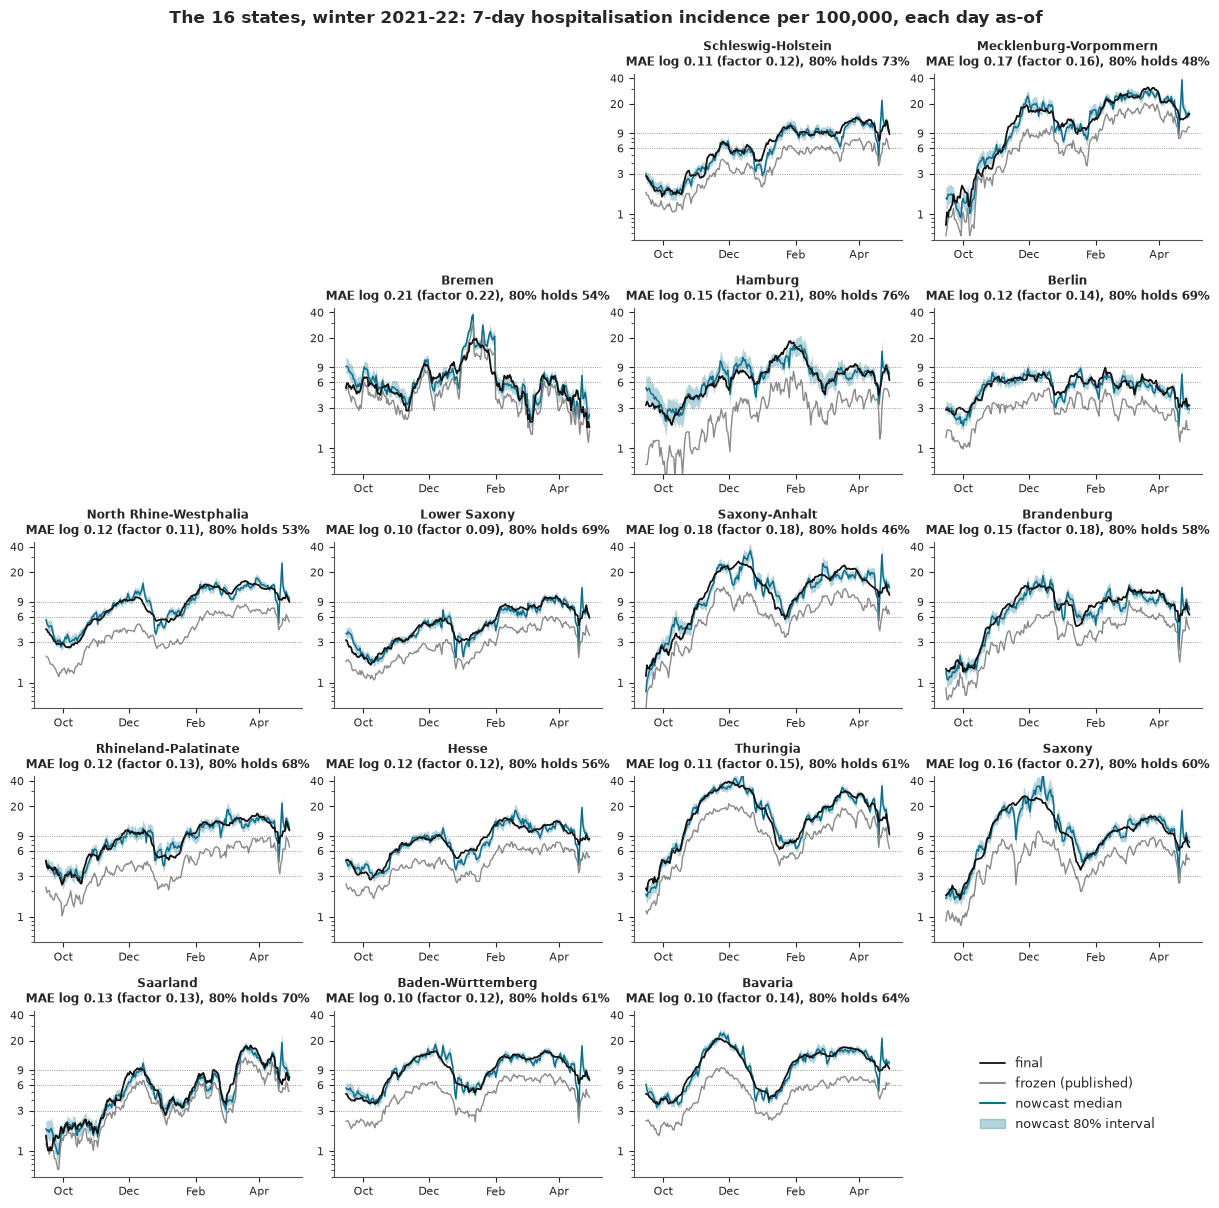

In [17]:
TILES = {"DE-SH": (0, 2), "DE-MV": (0, 3), "DE-HB": (1, 1), "DE-HH": (1, 2), "DE-BE": (1, 3), "DE-NW": (2, 0),
         "DE-NI": (2, 1), "DE-ST": (2, 2), "DE-BB": (2, 3), "DE-RP": (3, 0), "DE-HE": (3, 1), "DE-TH": (3, 2),
         "DE-SN": (3, 3), "DE-SL": (4, 0), "DE-BW": (4, 1), "DE-BY": (4, 2)}
fig, axes = plt.subplots(5, 4, figsize=(12, 12), sharex=True, sharey=True)
for ax in axes.ravel():
    ax.set_visible(False)
for state, (r, c) in TILES.items():
    s, ax = STATES.index(state), axes[r, c]
    ax.set_visible(True)
    ax.fill_between(DATES, q[1, s], q[5, s], color=MODEL, alpha=0.3, lw=0)
    ax.plot(DATES, q[3, s], color=MODEL, lw=1.1)
    ax.plot(DATES, frozen[s], color=FROZEN, lw=1.0)
    ax.plot(DATES, final[s], color=FINAL, lw=1.3)
    for tau in TAUS:
        ax.axhline(tau, color="#777777", lw=0.6, ls=":")
    inside = ((q[1, s] <= final[s]) & (final[s] <= q[5, s])).mean()
    ax.set_title(f"{NAMES[state]}\nMAE log {scores['by_state_mae'][state]['model']:.2f} (factor "
                 f"{scores['by_state_mae'][state]['factor']:.2f}), 80% holds {inside:.0%}", fontsize=8.5)
    ax.set(yscale="log", ylim=(0.5, 45))
    ax.set_yticks([1, 3, 6, 9, 20, 40], ["1", "3", "6", "9", "20", "40"])
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(10, 12, 2, 4)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.tick_params(labelsize=8, labelbottom=True, labelleft=True)
legend = fig.add_subplot(5, 4, 20)
legend.axis("off")
legend.legend(handles=[Line2D([], [], color=FINAL, lw=1.3, label="final"),
                       Line2D([], [], color=FROZEN, label="frozen (published)"),
                       Line2D([], [], color=MODEL, label="nowcast median"),
                       plt.Rectangle((0, 0), 1, 1, color=MODEL, alpha=0.3, label="nowcast 80% interval")],
              loc="center", frameon=False, fontsize=9)
fig.suptitle("The 16 states, winter 2021-22: 7-day hospitalisation incidence per 100,000, each day as-of",
             fontsize=12)
fig.get_layout_engine().set(h_pad=0.06);

Two things stand out. The nowcast follows the final value far more closely than the published one, in
every state. And the blue band is often too narrow: the black line leaves it for weeks at a time, worst in
Saxony-Anhalt, Mecklenburg-Vorpommern, North Rhine-Westphalia and Bremen, where the 80% interval held the
truth on 46-54% of days. The spikes in late April are Easter, a second holiday the model does not know:

In [18]:
easter = (DATES >= np.datetime64("2022-04-14")) & (DATES <= np.datetime64("2022-04-24"))
easter_ratio = np.median(q[3][:, easter] / final[:, easter], axis=0)
print("Easter 2022 (15-18 April): median over states of nowcast median / final, by as-of date")
print("  " + ", ".join(f"{pd.Timestamp(d):%d %b} {r:.2f}" for d, r in zip(DATES[easter], easter_ratio)))

Easter 2022 (15-18 April): median over states of nowcast median / final, by as-of date
  14 Apr 1.06, 15 Apr 1.10, 16 Apr 0.84, 17 Apr 0.81, 18 Apr 0.74, 19 Apr 0.57, 20 Apr 0.98, 21 Apr 1.47, 22 Apr 2.47, 23 Apr 1.32, 24 Apr 1.15


On 19 April, the day after Easter Monday, the nowcast stood at 0.57 of the final value, and three days
later it overshot to 2.5 times. That fits reports pausing over the holiday and the backlog then being read
as growth. An interval that misses like this is too narrow, which is the next question.

## 6 · Is it a calibrated probability? Failure 3

An 80% interval should hold the truth 80% of the time. Coverage is the share of state-days whose final
value fell inside the interval. Days within a state are strongly dependent, because neighbouring 7-day
sums share six days of cases, so the bands drawn below use one effective observation per state and week,
about 32 per state: a rough allowance, wider than a naive binomial.

In [19]:
cov = scores["coverage"]
for name, part in (("whole window", cov["whole"]), ("Delta", cov["by_wave"]["Delta"]),
                   ("BA.1", cov["by_wave"]["BA.1"]), ("BA.2", cov["by_wave"]["BA.2"])):
    print(f"{name:>13}: 50% interval holds {part['50']:.2f}, 80% {part['80']:.2f}, 95% {part['95']:.2f}")
print(f"From 2021-12-17, raw {cov['from_recal_start_raw']['50']:.2f} / {cov['from_recal_start_raw']['80']:.2f} / "
      f"{cov['from_recal_start_raw']['95']:.2f}; recalibrated {cov['from_recal_start_recalibrated']['50']:.2f} / "
      f"{cov['from_recal_start_recalibrated']['80']:.2f} / {cov['from_recal_start_recalibrated']['95']:.2f}; "
      f"median widening factor {cov['k_median']:.2f}")
held = scores["held_out"]
print(f"Cells revealed after the as-of date, predicted without a refit: {held['cells']:,} cells, 80% interval "
      f"holds {held['coverage_80']:.2f}; share of PIT values in the middle decile {held['pit_deciles'][4]:.2f}")
rki = scores["rki"]
print(f"RKI's real-time nowcast, {rki['state_days']:,} state-days from December: MAE log {rki['mae_log']:.3f} "
      f"(model {rki['model_mae_log_same_days']:.3f}, factor {rki['factor_mae_log_same_days']:.3f}); 95% interval "
      f"holds {rki['cover_95']:.2f} (model {rki['model_cover_95_same_days']:.2f})")
width = after["rki_width_95_over_mean"]
print(f"Width of the 95% interval over its centre (added after the run): RKI median {width['median']:.0%} "
      f"(10th-90th percentile {width['q10']:.0%}-{width['q90']:.0%}), the nowcast {after['model_width_95_over_median']:.0%}")

 whole window: 50% interval holds 0.36, 80% 0.62, 95% 0.80
        Delta: 50% interval holds 0.40, 80% 0.66, 95% 0.85
         BA.1: 50% interval holds 0.34, 80% 0.59, 95% 0.77
         BA.2: 50% interval holds 0.34, 80% 0.58, 95% 0.76
From 2021-12-17, raw 0.34 / 0.59 / 0.76; recalibrated 0.45 / 0.72 / 0.88; median widening factor 1.40
Cells revealed after the as-of date, predicted without a refit: 354,368 cells, 80% interval holds 0.90; share of PIT values in the middle decile 0.26
RKI's real-time nowcast, 2,432 state-days from December: MAE log 0.089 (model 0.139, factor 0.152); 95% interval holds 0.30 (model 0.77)
Width of the 95% interval over its centre (added after the run): RKI median 8% (10th-90th percentile 5%-18%), the nowcast 41%


The intervals are too narrow, and by a lot: the 80% interval held the truth 62% of the time, the 95%
interval 80%. E38 found the same, and so did the hub's comparison (Wolffram et al. 2023). Where does it
come from? A check that reuses the fitted totals on cells already seen cannot fail, so the run used one that
can: predict the cells revealed *after* the as-of date, with no refit. At the level of single cells the
model is, if anything, too cautious (90% inside an 80% interval, and PIT values piled in the middle). But a
single cell's spread is mostly negative-binomial count noise, so this check cannot tell a wrong level from
a wrong delay: what it shows is that the narrowness comes from errors shared across cells, the last week's
level, growth or drift in reporting speed, which a 7-day sum adds up instead of averaging away.

**Recalibration on the past only.** A forecaster in December could widen each interval by a factor $k$
learned from earlier dates whose truth was already known, at least 80 days old. On each date $k$ is the
80th percentile of the old standardised errors, at least 1, applied on the log scale around the median.
Nothing is known 80 days back before 17 December 2021, so recalibration starts there. It helps, raising
80% coverage from 0.59 to 0.72 on the same days, and it does not get there. RKI's own real-time nowcast
has a smaller log error than ours (0.089 against 0.139), but the two are not like for like. Its earliest
value in the hub was made 3 days after ours, with 3 more days of reports, and our own nowcast at that
horizon was not stored. And its 95% intervals are a median 8% of its mean wide against 41% of the median for ours, which
looks like an interval for a smoothed estimate rather than for the final value; it held the truth 30% of
the time. A probability from either, read at face value, would have misled.

80%: band 0.69-0.91 for 32 weeks, raw states below it 13; lower edge 0.63 for the 19 recalibrated weeks, states below it 4
95%: band 0.88-1.00 for 32 weeks, raw states below it 15; lower edge 0.84 for the 19 recalibrated weeks, states below it 1


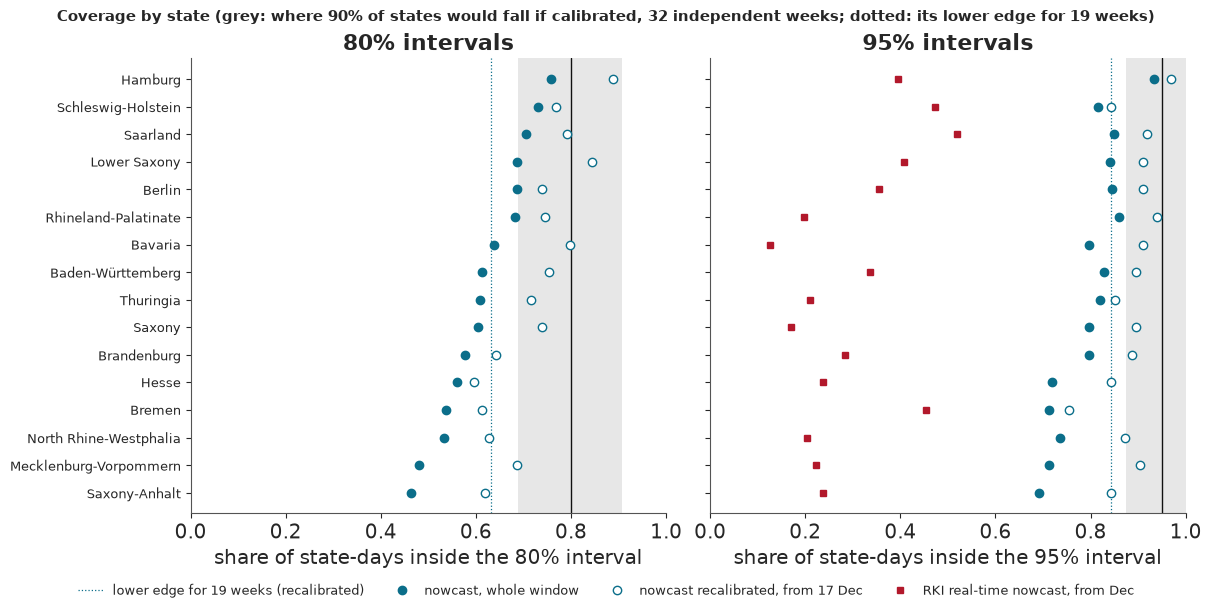

In [20]:
order_cov = sorted(STATES, key=lambda s: cov["by_state"][s]["80"])
eff_n = round(len(DATES) / 7)  # whole window: about 32 independent weeks per state
eff_recal = round(int((DATES >= np.datetime64("2021-12-17")).sum()) / 7)  # recalibrated: 19 weeks
below = {}
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
for ax, level, other in ((left, "80", None), (right, "95", "rki")):
    nominal = int(level) / 100
    lo_b, hi_b = stats.binom.ppf([0.05, 0.95], eff_n, nominal) / eff_n
    lo_r = stats.binom.ppf(0.05, eff_recal, nominal) / eff_recal
    ax.axvspan(lo_b, hi_b, color=MUTED, alpha=0.35, lw=0)
    ax.axvline(lo_r, color=MODEL, lw=0.9, ls=":", label=f"lower edge for {eff_recal} weeks (recalibrated)")
    ax.axvline(nominal, color=FINAL, lw=1)
    y = np.arange(16)
    ax.plot([cov["by_state"][s][level] for s in order_cov], y, "o", color=MODEL, label="nowcast, whole window")
    ax.plot([cov["recalibrated_by_state"][s][level] for s in order_cov], y, "o", mfc="white", color=MODEL,
            label="nowcast recalibrated, from 17 Dec")
    if other:
        ax.plot([rki["by_state_cover_95"][s] for s in order_cov], y, "s", color=RKI, ms=5,
                label="RKI real-time nowcast, from Dec")
    ax.set(xlabel=f"share of state-days inside the {level}% interval", xlim=(0, 1), title=f"{level}% intervals")
    below[level] = (sum(cov["by_state"][s][level] < lo_b for s in STATES),
                    sum(cov["recalibrated_by_state"][s][level] < lo_r for s in STATES))
    print(f"{level}%: band {lo_b:.2f}-{hi_b:.2f} for {eff_n} weeks, raw states below it {below[level][0]}; lower "
          f"edge {lo_r:.2f} for the {eff_recal} recalibrated weeks, states below it {below[level][1]}")
left.set_yticks(range(16), [NAMES[s] for s in order_cov], fontsize=9)
fig.legend(*right.get_legend_handles_labels(), fontsize=9, frameon=False, ncol=4, loc="outside lower center")
fig.suptitle(f"Coverage by state (grey: where 90% of states would fall if calibrated, {eff_n} independent weeks; "
             f"dotted: its lower edge for {eff_recal} weeks)", fontsize=11);

At 80%, 13 of 16 states sit below the band before recalibration. The recalibrated dots cover only the 19
weeks from 17 December, so their band is wider, with a lower edge of 0.63: 4 states sit below it. At 95%
the counts are 15 and 1. Only Hamburg, the slowest reporter, is near calibration throughout. RKI's nowcast
is far narrower again. This is the probability line of the standard set before the run, and it is not
met: whatever the probabilities are worth as alerts, which section 8 tests, they are not calibrated
chances.

## 7 · How much does hindsight flatter? Failure 2

A common shortcut in testing a nowcast is to estimate the delay distribution once, from the finished
triangle, and then replay the nowcast with it. That uses the future. To measure the cost, the run fitted
the delays on the finished window (25 September 2021 to 23 April 2022, every bin known), fixed the hazard
at its posterior mean, and refitted eight hard dates with only the level free. The eight dates were picked
by a rule on the data (cases near a threshold), written after the pilots had been seen.

Mean CRPS on 8 dates: honest 1.09, hindsight 0.77, 29% lower (the line for 'it barely matters' was 5%)
Mean log error: honest 0.143, hindsight 0.096
Without 23 April: hindsight CRPS 17% lower


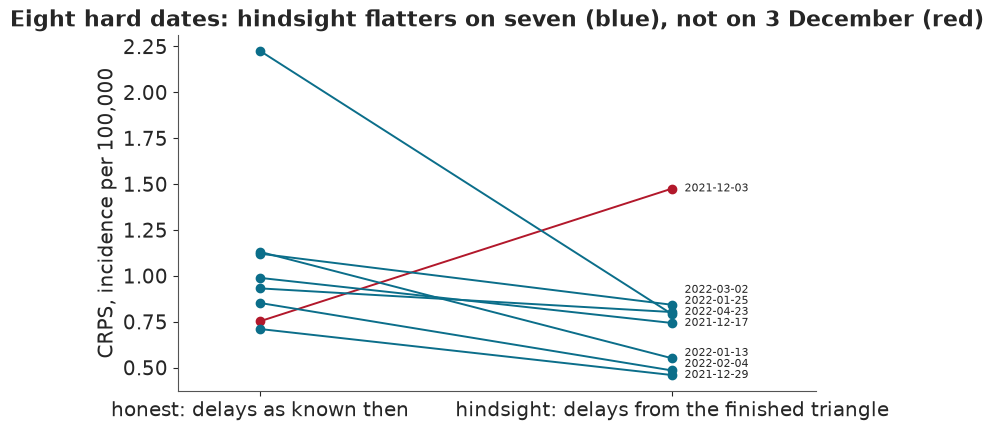

In [21]:
hind = scores["hindsight"]
hrows = pd.DataFrame(hind["rows"])
print(f"Mean CRPS on {hind['n']} dates: honest {hind['honest_crps']:.2f}, hindsight {hind['hindsight_crps']:.2f}, "
      f"{hind['crps_lower_by']:.0%} lower (the line for 'it barely matters' was 5%)")
print(f"Mean log error: honest {hrows['honest_mae'].mean():.3f}, hindsight {hrows['hindsight_mae'].mean():.3f}")
rest = hrows[hrows["date"] != "2022-04-23"]
hind_rest = 1 - rest["hindsight_crps"].mean() / rest["honest_crps"].mean()
print(f"Without 23 April: hindsight CRPS {hind_rest:.0%} lower")
fig, ax = plt.subplots(figsize=(8, 4.2))
label_y = np.sort(hrows["hindsight_crps"].to_numpy())
for k in range(1, len(label_y)):  # keep labels at least 0.06 apart
    label_y[k] = max(label_y[k], label_y[k - 1] + 0.06)
label_at = dict(zip(hrows["hindsight_crps"].sort_values().index, label_y))
for i, r in hrows.iterrows():
    better = r["hindsight_crps"] < r["honest_crps"]
    ax.plot([0, 1], [r["honest_crps"], r["hindsight_crps"]], color=MODEL if better else RKI, lw=1.4, marker="o")
    ax.text(1.03, label_at[i], r["date"], fontsize=8, va="center")
ax.set_xticks([0, 1], ["honest: delays as known then", "hindsight: delays from the finished triangle"])
ax.set(xlim=(-0.2, 1.35), ylabel="CRPS, incidence per 100,000",
       title="Eight hard dates: hindsight flatters on seven (blue), not on 3 December (red)");

Hindsight cut the CRPS by 29%, far past the 5% that would have said it barely matters, and it flattered on
seven of eight dates, most on 23 April (2.23 to 0.79) and 13 January. Without 23 April the cut is 17%,
still far past 5%. Part of the gap is not the leak itself: the hindsight
fits hold the hazard at a single value, so their intervals carry no delay uncertainty at all, and on 3
December that made them worse. Either way, a nowcast tested with delays learned later reports a skill it
would not have had.

## 8 · Is it a better alarm? Failure 4

A better number need not be a better alarm. An alert raised when $P(\text{final} \ge \tau) \ge p_t$ is
scored by its **net benefit** per state-day,

$$\mathrm{NB}(p_t) = \frac{TP}{N} - \frac{FP}{N}\,\frac{p_t}{1-p_t},$$

where $TP$ counts alert-days on which the final value was above $\tau$ and $FP$ alert-days on which it was
not. The choice of $p_t$ is a statement of values: one correct alert-day is worth $(1-p_t)/p_t$ false
ones. At $p_t = 0.2$ the unit would accept four false alarm-days for each right one; at 0.5, one. A rule
with no probability, such as "factor at or above $\tau$", gives one line across all $p_t$. "Alert
everyone" and "alert no one" (zero) are the references. State-days are not independent, so the bands come
from a Bayesian bootstrap over the 37 state x wave clusters that held a crossing, and three waves are the
real sample.

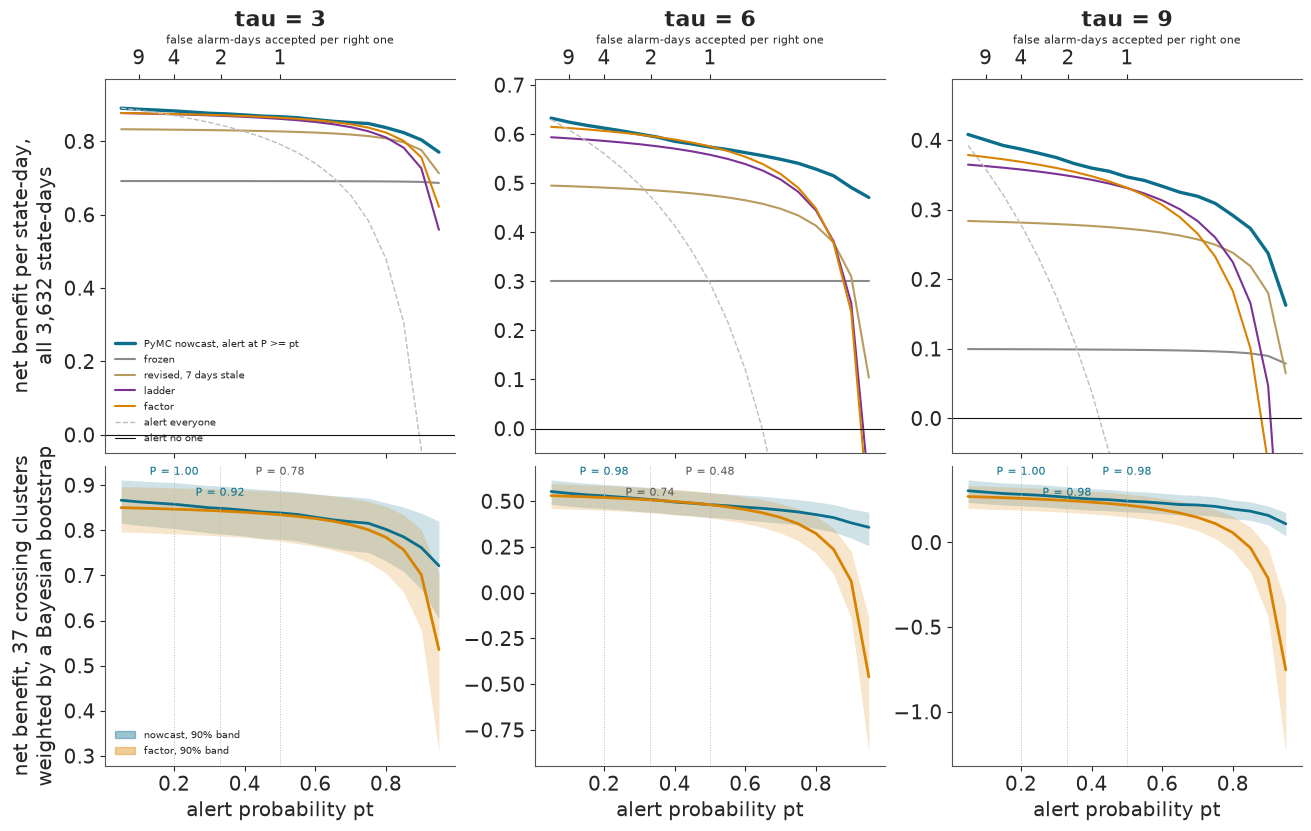

In [22]:
NB_SIGNALS = (("frozen", FROZEN, "frozen"), ("revised_7d_stale", STALE, "revised, 7 days stale"),
              ("ladder", LADDER, "ladder"), ("factor", FACTOR, "factor"))
fig, axes = plt.subplots(2, 3, figsize=(13, 8.2), sharex=True, height_ratios=(1.25, 1))
for col, tau in enumerate(TAUS):
    table = decision["net_benefit"][f"tau{tau}"]["all"]
    pts = np.array([r["pt"] for r in table["model"]])
    ax = axes[0, col]
    ax.plot(pts, [r["point_48"] for r in table["model"]], color=MODEL, lw=2.4, label="PyMC nowcast, alert at P >= pt")
    for name, colour, label in NB_SIGNALS:
        ax.plot(pts, [r["point_48"] for r in table[name]], color=colour, lw=1.5, label=label)
    ax.plot(pts, [r["point_48"] for r in table["treat_all"]], color=MUTED, lw=1, ls="--", label="alert everyone")
    ax.axhline(0, color=FINAL, lw=0.8, label="alert no one")
    best = max(r["point_48"] for name in ("model", "factor") for r in table[name])
    ax.set(title=f"tau = {tau}", ylim=(-0.05, best + 0.08))
    top = ax.secondary_xaxis("top", functions=(lambda p: (1 - p) / np.clip(p, 1e-3, None), lambda r: 1 / (1 + r)))
    top.set_ticks([9, 4, 2, 1])
    top.set_xlabel("false alarm-days accepted per right one", fontsize=8)
    ax = axes[1, col]
    for name, colour in (("model", MODEL), ("factor", FACTOR)):
        ax.fill_between(pts, [r["q05"] for r in table[name]], [r["q95"] for r in table[name]], color=colour,
                        alpha=0.2, lw=0)
        ax.plot(pts, [r["mean"] for r in table[name]], color=colour, lw=2)
    for k, (pt, v) in enumerate(decision["net_benefit"][f"tau{tau}"]["wins"].items()):
        ax.axvline(float(pt), color=MUTED, lw=0.7, ls=":")
        ax.text(float(pt), 1.0 - 0.07 * (k % 2), f"P = {v['p_model_beats_factor']:.2f}", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=8, color=MODEL if v["win"] else "#555555")
    ax.set(xlabel="alert probability pt")
axes[0, 0].set_ylabel("net benefit per state-day,\nall 3,632 state-days")
axes[1, 0].set_ylabel("net benefit, 37 crossing clusters\nweighted by a Bayesian bootstrap")
axes[0, 0].legend(fontsize=7.5, frameon=False, loc="lower left")
axes[1, 0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=MODEL, alpha=0.4, label="nowcast, 90% band"),
                           plt.Rectangle((0, 0), 1, 1, color=FACTOR, alpha=0.4, label="factor, 90% band")],
                  fontsize=7.5, frameon=False, loc="lower left");

The top row is net benefit on all state-days. Over most of the range the frozen line is the lowest of the
rules: a signal that rarely alarms has little to give. Only at the strictest values, $p_t = 0.9$ for
$\tau = 6$ and 9 and 0.95 for $\tau = 3$, does it pass the factor and the ladder, whose false alarms are
then charged at nine or more times a right alert. At $\tau = 3$ most days are above the line, so all
the curves sit high and close together. The nowcast's curve is the highest or level with the highest
almost everywhere, and alone it stays high at large $p_t$: a strict alert probability still catches the
clear days, while each false alarm of a fixed rule is charged ever more heavily. The bottom row repeats the nowcast and the factor with each of the 37
crossing clusters weighted by the bootstrap, which is how the test set before the run was scored: a probability of at
least 0.9 that the nowcast beats the factor, at three named values of $p_t$ (dotted, with that
probability printed):

In [23]:
for tau in TAUS:
    w = decision["net_benefit"][f"tau{tau}"]["wins"]
    cells = ", ".join(f"pt {pt}: P = {v['p_model_beats_factor']:.2f}{' (wins)' if v['win'] else ''}"
                      for pt, v in w.items())
    print(f"tau {tau}: {cells}")
bar = decision["bar_net_benefit"]
print(f"Wins of 3: tau 3 {bar['tau3']}, tau 6 {bar['tau6']}, tau 9 {bar['tau9']}; with recalibrated "
      f"probabilities from 17 Dec: {bar['tau3_recal']}, {bar['tau6_recal']}, {bar['tau9_recal']}. "
      f"Beats the factor on net benefit: {bar['beats_factor']}")

tau 3: pt 0.2: P = 1.00 (wins), pt 0.33: P = 0.92 (wins), pt 0.5: P = 0.78
tau 6: pt 0.2: P = 0.98 (wins), pt 0.33: P = 0.74, pt 0.5: P = 0.48
tau 9: pt 0.2: P = 1.00 (wins), pt 0.33: P = 0.98 (wins), pt 0.5: P = 0.98 (wins)
Wins of 3: tau 3 2, tau 6 1, tau 9 3; with recalibrated probabilities from 17 Dec: 3, 1, 3. Beats the factor on net benefit: True


The nowcast beats the factor at two of three cost ratios at $\tau = 3$, all three at $\tau = 9$, and only
the most alarm-tolerant one at $\tau = 6$. The standard set before the run asked for two of three ratios on
two of three thresholds, so the net-benefit line is met; recalibrating the probabilities does not change
the verdict.

Two checks added after the run qualify it. The bootstrap weights only the 37 state x wave cells that held a
crossing; the other 11 hold 676 state-days, and there the nowcast is behind the factor at every threshold
and every named $p_t$. And the test sets a probability rule, which can choose where to stand, against a
fixed rule, which cannot. The factor can be made probabilistic for free: multiply the published value by
each of the 28 recent ratios it already uses, and by the tail ratio of weeks complete at 80 days, and read
$P(\text{final} \ge \tau)$ as the share of the 28 products above $\tau$. Everything in it is known on the day.
Scored with the same bootstrap:

In [24]:
for tau in TAUS:
    pf_rows = after["prob_factor"][f"tau{tau}"]["rows"]
    print(f"tau {tau}: P(nowcast beats probabilistic factor) "
          + ", ".join(f"pt {pt} {v['p_model_beats_prob_factor']:.2f}" for pt, v in pf_rows.items())
          + f"; wins {after['prob_factor'][f'tau{tau}']['wins']} of 3; outside the clusters, nowcast minus factor "
          + ", ".join(f"{v['outside_clusters_model_minus_factor']:+.0f}" for v in pf_rows.values()))
pf_scores = after["prob_factor_scores"]
print(f"Probabilistic factor as a forecast: CRPS {pf_scores['crps']:.2f} (nowcast "
      f"{scores['signals']['model']['crps']:.2f}, factor {scores['signals']['factor']['crps']:.2f}); 80% interval "
      f"holds {pf_scores['cover_80']:.2f}, 95% {pf_scores['cover_95']:.2f}")

tau 3: P(nowcast beats probabilistic factor) pt 0.2 0.17, pt 0.33 0.36, pt 0.5 0.77; wins 0 of 3; outside the clusters, nowcast minus factor -2, -2, -2
tau 6: P(nowcast beats probabilistic factor) pt 0.2 0.26, pt 0.33 0.54, pt 0.5 0.61; wins 0 of 3; outside the clusters, nowcast minus factor -5, -5, -5
tau 9: P(nowcast beats probabilistic factor) pt 0.2 0.98, pt 0.33 0.95, pt 0.5 0.98; wins 3 of 3; outside the clusters, nowcast minus factor -4, -11, -16
Probabilistic factor as a forecast: CRPS 1.14 (nowcast 0.94, factor 1.43); 80% interval holds 0.53, 95% 0.67


Against the probabilistic factor the nowcast wins none of the three cost ratios at $\tau = 3$ or 6, and all
three at $\tau = 9$, so on this comparison the net-benefit line would not be met. Outside the clusters the
nowcast is behind the plain factor by 2 to 16 in the numerator of net benefit. As a forecast the nowcast is
still clearly better (CRPS 0.94 against 1.14), and the probabilistic factor is worse calibrated still (its
80% interval held 53%). So the nowcast is the better number overall, but as an alarm its advantage is
clear only at $\tau = 9$; at 3 and 6 a factor that costs nothing does as well.

### Who called each crossing, and when

Net benefit counts days. A ministry also cares about each crossing: how many days after the final series
rose above $\tau$ (for three days, after three below) did each signal raise the alert? Negative means
early. The search starts 10 days before each crossing, so early calls are censored at $-10$, and an alert
raised that early may be noise as much as foresight; an alert already up on that first day is counted
apart. The search ends with the episode, on the first of three days below $\tau$: an alert raised after
that belongs to a later crossing. The definition fixed before the run searched to the end of the window
instead, which credits a later episode's alert to an earlier crossing; it is reproduced below and
printed beside, but the episode is the reading used here, chosen after the run.

In [25]:
def crossings(up):
    return [(s, t) for s in range(16) for t in range(3, up.shape[1] - 2)
            if up[s, t : t + 3].all() and not up[s, t - 3 : t].any()]


def episode_end(up, s, t):
    """The first day from t on that starts three days below tau; the end of the window if none."""
    return next((u for u in range(t, up.shape[1] - 2) if not up[s, u : u + 3].any()), up.shape[1])


def first_alert(alert, s, t, end):
    hit = np.flatnonzero(alert[s, max(0, t - 10) : end])
    return int(hit[0]) + max(0, t - 10) - t if hit.size else None


late_rows = []
for tau in TAUS:
    up = final >= tau
    cross = crossings(up)
    for w, (wname, _) in enumerate(WAVES):
        part = [x for x in cross if wave[x[1]] == w]
        stored = decision["lateness"][f"tau{tau}"][wname]
        assert len(part) == stored["frozen"]["n"], "crossings recomputed here must match the stored ones"
        for name in ("frozen", "factor", "model_p0.5"):
            alert = (dict(frozen=frozen, factor=factor)[name] >= tau if name != "model_p0.5"
                     else p_cross[TAUS.index(tau)] >= 0.5)
            window_late = [first_alert(alert, s, t, final.shape[1]) for s, t in part]
            assert [x for x in window_late if x is not None] == stored[name]["late"], "the stored reading reproduces"
            for (s, t), whole in zip(part, window_late):
                late_rows.append({"tau": tau, "wave": wname, "state": STATES[s], "date": DATES[t], "t": t, "signal": name,
                                  "late": first_alert(alert, s, t, episode_end(up, s, t)), "to_window_end": whole,
                                  "already_up": bool(alert[s, max(0, t - 10)])})
late = pd.DataFrame(late_rows)
late[["late", "to_window_end"]] = late[["late", "to_window_end"]].astype(float)  # NaN: never called
summary = late.groupby(["tau", "wave", "signal"])["late"].agg(
    median="median", never=lambda x: int(x.isna().sum())).unstack("signal")
print("Within the episode:")
print(summary.to_string())
never = late.groupby(["tau", "signal"]).agg(n=("late", "size"), never=("late", lambda x: int(x.isna().sum())),
                                            never_to_window_end=("to_window_end", lambda x: int(x.isna().sum())),
                                            already_up=("already_up", "sum")).unstack("signal")
print("\nNever called, within the episode and to the end of the window; alert already up 10 days before:")
print(never.to_string())
print("\nThe nowcast's misses within the episode:")
for _, r in late[(late["signal"] == "model_p0.5") & late["late"].isna()].iterrows():
    same = (late["tau"] == r["tau"]) & (late["state"] == r["state"]) & (late["date"] == r["date"])
    by_factor = late.loc[same & (late["signal"] == "factor"), "late"].iloc[0]
    length = episode_end(final >= r["tau"], STATES.index(r["state"]), r["t"]) - r["t"]
    print(f"  tau {r['tau']}: {NAMES[r['state']]} from {pd.Timestamp(r['date']):%Y-%m-%d}, an episode of {length} "
          f"days; the factor: {'never' if np.isnan(by_factor) else f'{by_factor:+.0f} days'}")

Within the episode:
          median                    never                  
signal    factor frozen model_p0.5 factor frozen model_p0.5
tau wave                                                   
3   BA.1   -10.0  -10.0      -10.0      0      0          0
    BA.2   -10.0  -10.0      -10.0      0      0          0
    Delta   -3.5   10.0       -4.0      1      2          1
6   BA.1    -7.0   19.0       -7.0      0      5          1
    BA.2    -3.5    4.0      -10.0      0      4          0
    Delta   -4.0   14.0       -5.0      0      5          0
9   BA.1    -7.0   15.5        1.0      0     11          1
    BA.2    -5.0    4.0       -4.0      0      3          0
    Delta    1.0   15.0        2.0      1      5          0

Never called, within the episode and to the end of the window; alert already up 10 days before:
            n                    never                   never_to_window_end                   already_up                  
signal factor frozen model_p0.5 factor 

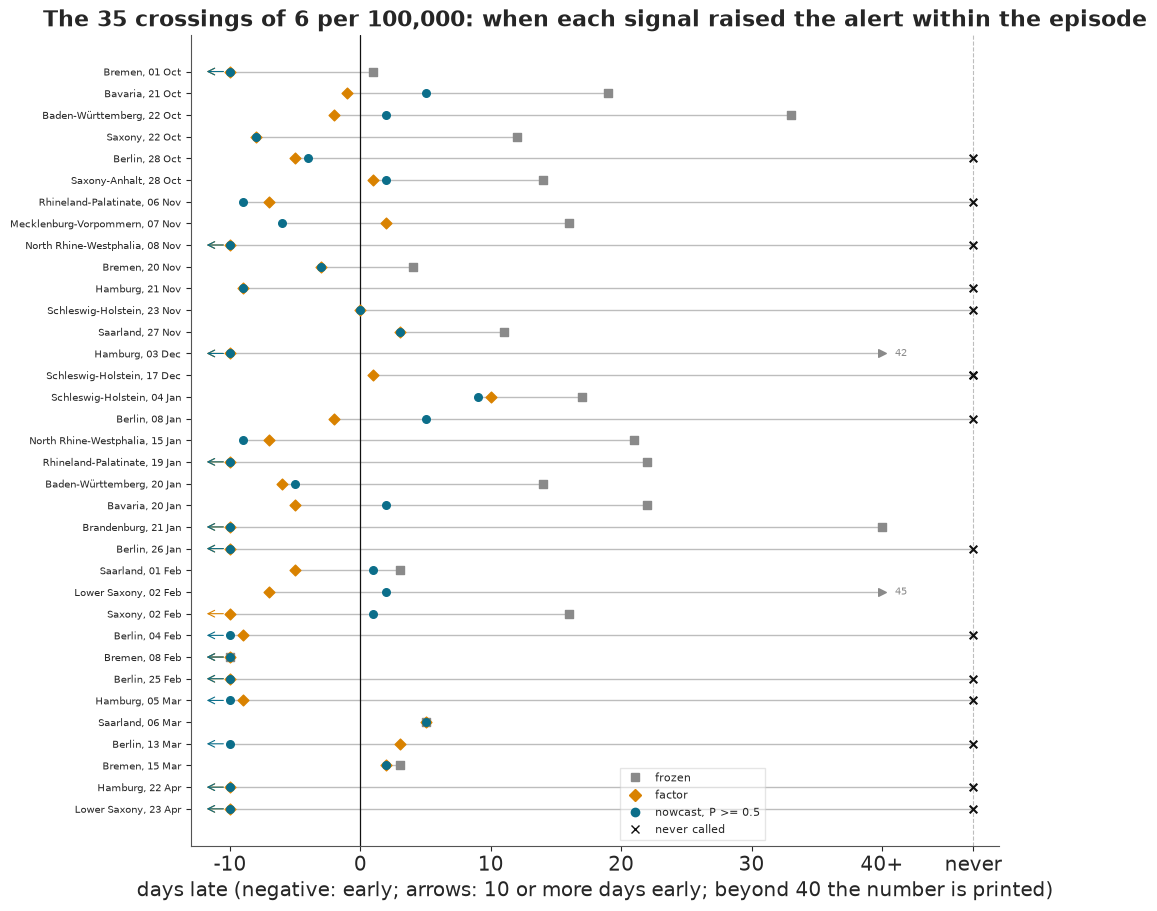

In [26]:
six = late[late["tau"] == 6].pivot(index=["date", "state"], columns="signal", values="late").reset_index()
six = six.sort_values("date").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 9))
CAP, NEVER = 40, 47
for i, r in six.iterrows():
    values = {k: (NEVER if pd.isna(r[k]) else min(r[k], CAP)) for k in ("frozen", "factor", "model_p0.5")}
    ax.plot([min(values.values()), max(values.values())], [i, i], color=MUTED, lw=1, zorder=1)
    for k, colour, marker in (("frozen", FROZEN, "s"), ("factor", FACTOR, "D"), ("model_p0.5", MODEL, "o")):
        v = values[k]
        shown = "x" if v == NEVER else (">" if v == CAP and r[k] > CAP else marker)
        ax.scatter(v, i, color=FINAL if v == NEVER else colour, marker=shown, s=30, zorder=3)
        if v == CAP and r[k] > CAP:
            ax.text(CAP + 1, i, f"{r[k]:.0f}", fontsize=7, va="center", color=colour)
        if v == -10:
            ax.annotate("", (v - 2.0, i), (v - 0.3, i), arrowprops=dict(arrowstyle="->", color=colour, lw=0.8))
ax.axvline(0, color=FINAL, lw=0.9)
ax.axvline(NEVER, color=MUTED, lw=0.8, ls="--")
ax.set_xticks([-10, 0, 10, 20, 30, 40, NEVER], ["-10", "0", "10", "20", "30", "40+", "never"])
ax.set_yticks(range(len(six)), [f"{NAMES[s]}, {pd.Timestamp(d):%d %b}" for d, s in zip(six["date"], six["state"])],
              fontsize=7.5)
ax.set(xlabel="days late (negative: early; arrows: 10 or more days early; beyond 40 the number is printed)",
       xlim=(-13, NEVER + 2),
       title="The 35 crossings of 6 per 100,000: when each signal raised the alert within the episode")
ax.invert_yaxis()
ax.legend(handles=[Line2D([], [], marker="s", ls="", color=FROZEN, label="frozen"),
                   Line2D([], [], marker="D", ls="", color=FACTOR, label="factor"),
                   Line2D([], [], marker="o", ls="", color=MODEL, label="nowcast, P >= 0.5"),
                   Line2D([], [], marker="x", ls="", color=FINAL, label="never called")],
          fontsize=8, frameon=True, loc="lower center", bbox_to_anchor=(0.62, 0.0));

The frozen value called the crossings of 6 in Delta and BA.1 two to three weeks late at the median (14 and
19 days), and it never called 14 of the 35 before the episode ended: 5 of 14 in Delta, 5 of 15 in BA.1 and
4 of 6 in BA.2, six of them in Berlin. Searching to the end of the window, as the definition fixed before
the run did, it would have "called" five of these 35 to 96 days late, in a later episode. The factor and
the nowcast called most crossings before they happened or within a few days. The nowcast at $P \ge 0.5$
missed 1 of 17 crossings of 3, 1 of 35 of 6 and 1 of 29 of 9, each an episode of three to five days; the
factor missed 1, 0 and 1. At
$\tau = 6$ that was Schleswig-Holstein's five days above 6 from 17 December, which the factor called a day
late. Many early calls are alerts that were already up: 10 days before the crossing the nowcast's alert was
on for 13 of the 35 crossings of 6, the factor's for 11. Among the wave medians the nowcast's largest loss
is $\tau = 9$ in BA.1, a day late where the factor was a week early; it was also a day later than the
factor at $\tau = 9$ in Delta and BA.2.

### False alarms against misses, and flapping

Moving the alert probability trades false alarm-days against missed days. The curve shows the trade for
the nowcast at each threshold, with the fixed rules as points.

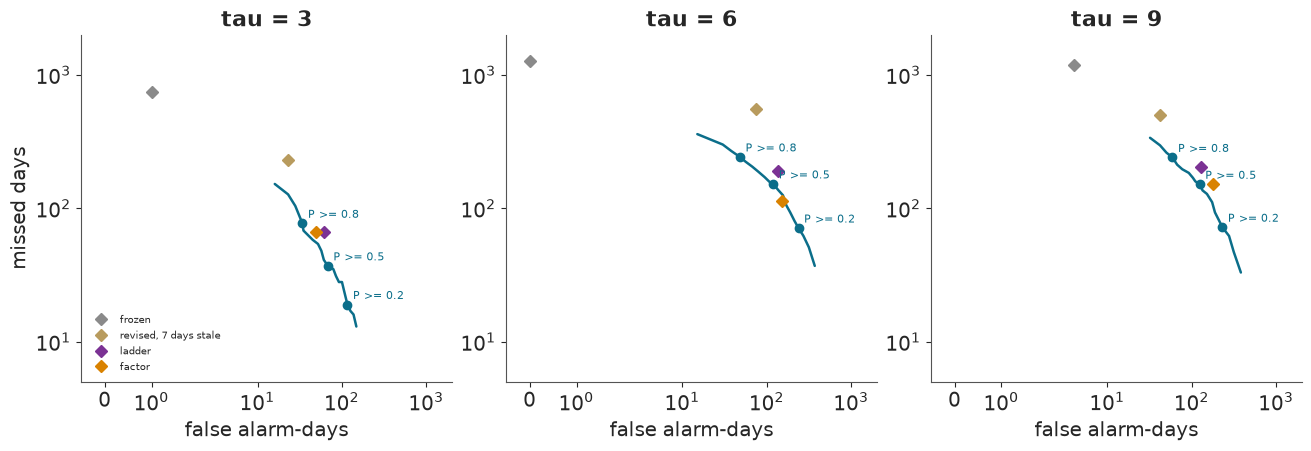

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, tau in zip(axes, TAUS):
    trade = decision["fp_fn_tradeoff"][f"tau{tau}"]
    ax.plot([r["fp_days"] for r in trade], [r["fn_days"] for r in trade], "-", color=MODEL, lw=1.8)
    for r in trade:
        if r["p"] in (0.2, 0.5, 0.8):
            ax.plot(r["fp_days"], r["fn_days"], "o", color=MODEL)
            ax.annotate(f"P >= {r['p']}", (r["fp_days"], r["fn_days"]), xytext=(4, 4), textcoords="offset points",
                        fontsize=8, color=MODEL)
    for name, colour, label in NB_SIGNALS:
        fp, fn = scores["signals"][name][f"tau{tau}"]
        ax.plot(fp, fn, "D", color=colour, ms=6, label=label)
    ax.set(xscale="symlog", yscale="symlog", xlabel="false alarm-days", title=f"tau = {tau}",
           xlim=(-0.5, 2000), ylim=(5, 2000))
axes[0].set_ylabel("missed days")
axes[0].legend(fontsize=7.5, frameon=False, loc="lower left");

The fixed rules sit close to the nowcast's curve: at the false-alarm rate of the factor, the nowcast misses
about a quarter fewer days at $\tau = 3$ (about 50 against 66), a few more at $\tau = 6$ and fewer at
$\tau = 9$. What the nowcast adds is the choice
of where on the curve to stand.

An alert that goes up and down with each day's number is hard to act on. Raising it the first day the
signal is up and lowering it only after $r$ days in a row below is a **release rule**; one press report
mentions release after 5 days below, though how states applied it was not checked.

In [28]:
rel = decision["release"]["tau6"]
rel_frame = pd.DataFrame([[label, *[f"{rel[key][r]['alert_periods']} / {rel[key][r]['false_alarm_days']} / "
                                    f"{rel[key][r]['missed_days']}" for r in ("1", "3", "5")]]
                          for key, label in (("frozen", "frozen"), ("factor", "factor"),
                                             ("model_p0.2", "nowcast, P >= 0.2"), ("model_p0.5", "nowcast, P >= 0.5"))],
                         columns=["tau 6", "no release rule", "release after 3", "release after 5"])
print("Each cell: alert periods / false alarm-days / missed days, 16 states, 227 days")
display(markdown_table(rel_frame))
sh = final[STATES.index("DE-SH")] >= 9
print(f"Schleswig-Holstein's final series rose through 9 on {int((sh[1:] & ~sh[:-1]).sum())} separate days")

Each cell: alert periods / false alarm-days / missed days, 16 states, 227 days


| tau 6 | no release rule | release after 3 | release after 5 |
|---|---|---|---|
| frozen | 84 / 0 / 1262 | 56 / 1 / 1124 | 46 / 6 / 1039 |
| factor | 84 / 153 / 113 | 50 / 231 / 71 | 45 / 288 / 59 |
| nowcast, P >= 0.2 | 98 / 237 / 71 | 57 / 341 / 32 | 40 / 408 / 23 |
| nowcast, P >= 0.5 | 98 / 119 / 152 | 60 / 204 / 100 | 46 / 269 / 81 |

Schleswig-Holstein's final series rose through 9 on 8 separate days


Without a release rule the nowcast at $P \ge 0.5$ raised 98 separate alerts at $\tau = 6$ in 16 states over
seven months, about six per state: that is flapping, and even the truth flaps, as
Schleswig-Holstein's final series rose through 9 on eight separate days. Releasing after five days below
halves the alerts to 46 and moves days from missed (152 to 81) to false alarm (119 to 269). So failure 4
is half true here. The better forecast is also the better alarm than the fixed factor at most cost ratios,
though not than a probabilistic factor below $\tau = 9$; used naively it flaps, and the release rule
matters as much as the signal.

## 9 · Do age strata change an alert?

The thresholds act on all-age values, but cases of different ages report at different speeds, so a
nowcast of 96 state x age strata, summed to all ages, might do better. This is the heaviest fit of the
run: 968 parameters and about 102,000 cells, 15-18 minutes per date on the GPU, run on the same eight
hard dates.

5 of 384 alerts at P = 0.5 changed (16 states x 3 thresholds x 8 dates); largest change in P 0.54, median 0.00
Mean CRPS: strata 1.39, state model 1.09; worst strata date 2022-04-23 (CRPS 3.92, 80% coverage 0.00)


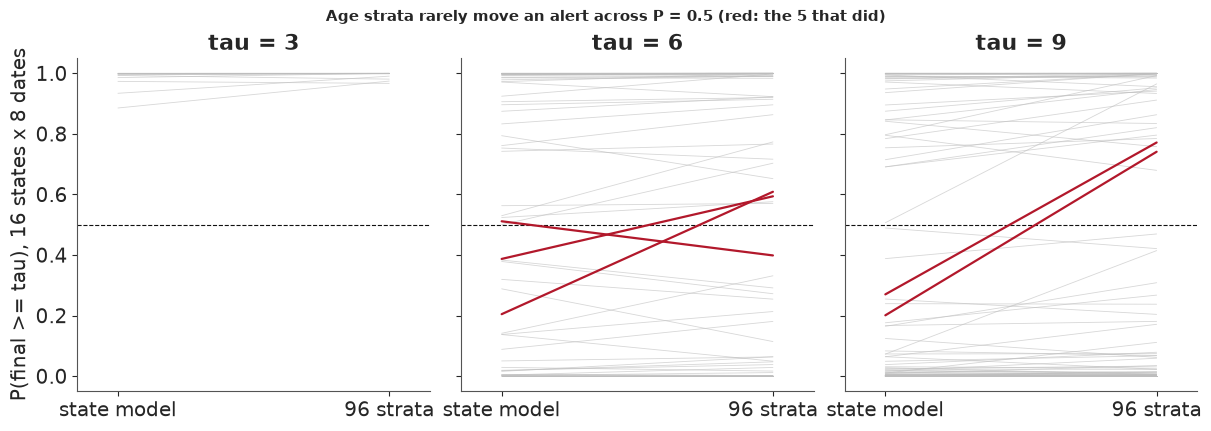

In [29]:
strata = scores["strata"]
srows = pd.DataFrame(strata["rows"])
print(f"{strata['alerts_changed']} of {strata['alerts_compared']} alerts at P = 0.5 changed (16 states x 3 "
      f"thresholds x {strata['n_dates']} dates); largest change in P {strata['dp_max']:.2f}, median "
      f"{strata['dp_median']:.2f}")
print(f"Mean CRPS: strata {srows['strata_crps'].mean():.2f}, state model {srows['state_crps'].mean():.2f}; "
      f"worst strata date {srows.loc[srows['strata_crps'].idxmax(), 'date']} (CRPS "
      f"{srows['strata_crps'].max():.2f}, 80% coverage {srows.loc[srows['strata_crps'].idxmax(), 'strata_cover_80']:.2f})")
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)
for ax, (j, tau) in zip(axes, enumerate(TAUS)):
    for row in strata["slope"]:
        a, b = np.array(row["p_state"][j]), np.array(row["p_strata"][j])
        flip = (a >= 0.5) != (b >= 0.5)
        for x, y, f in zip(a, b, flip):
            ax.plot([0, 1], [x, y], color=RKI if f else MUTED, lw=1.6 if f else 0.6, alpha=1 if f else 0.6,
                    zorder=3 if f else 1)
    ax.axhline(0.5, color=FINAL, lw=0.8, ls="--")
    ax.set_xticks([0, 1], ["state model", "96 strata"])
    ax.set(title=f"tau = {tau}", xlim=(-0.15, 1.15))
axes[0].set_ylabel("P(final >= tau), 16 states x 8 dates")
fig.suptitle("Age strata rarely move an alert across P = 0.5 (red: the 5 that did)", fontsize=11);

The strata moved 5 of 384 alerts across $P = 0.5$, and their CRPS was worse (1.39 against 1.09), worst on
23 April when their 80% intervals held none of the 16 states. The sampler passed all its checks on all
eight dates; the strata simply do not earn their place as a forecast here, with a third of the 96 strata
holding fewer than 500 cases from late November to April. The state model is the recommendation.

## 10 · What the unit should do

The last table picks, for each state and threshold, the signal and alert probability with the best net
benefit at $p_t = 0.33$ (two false alarm-days accepted per right one) over the whole window. It is
in-sample, chosen on the same days it is scored on, so it says which kind of rule suits a state, not what
that rule would earn next winter.

In [30]:
rule_rows = []
for s in STATES:
    cells = []
    for tau in TAUS:
        r = decision["rules"][f"tau{tau}"][s]
        name = {"model": f"nowcast P >= {r['alert_p']}", "revised_7d_stale": "revised, stale"}.get(r["signal"], r["signal"])
        cells.append(f"{name} ({r['net_benefit'] - r['factor_net_benefit']:+.3f}, {r['false_alarm_days']} FA)")
    rule_rows.append([NAMES[s], *cells])
display(markdown_table(pd.DataFrame(rule_rows, columns=["State", "tau 3", "tau 6", "tau 9"])))
counts = {tau: pd.Series([decision["rules"][f"tau{tau}"][s]["signal"] for s in STATES]).value_counts().to_dict()
          for tau in TAUS}
print("In brackets: net benefit minus the factor's, and false alarm-days. Best signal per threshold:", counts)

| State | tau 3 | tau 6 | tau 9 |
|---|---|---|---|
| Brandenburg | nowcast P >= 0.2 (+0.007, 1 FA) | nowcast P >= 0.1 (+0.016, 16 FA) | nowcast P >= 0.33 (+0.064, 13 FA) |
| Berlin | nowcast P >= 0.1 (+0.022, 10 FA) | nowcast P >= 0.1 (+0.010, 39 FA) | frozen (+0.013, 0 FA) |
| Baden-Württemberg | revised, stale (+0.004, 0 FA) | factor (+0.000, 9 FA) | factor (+0.000, 12 FA) |
| Bavaria | nowcast P >= 0.1 (+0.004, 0 FA) | nowcast P >= 0.2 (+0.013, 1 FA) | nowcast P >= 0.1 (+0.011, 4 FA) |
| Bremen | nowcast P >= 0.2 (+0.018, 12 FA) | nowcast P >= 0.33 (+0.022, 29 FA) | ladder (+0.015, 8 FA) |
| Hesse | factor (+0.000, 4 FA) | nowcast P >= 0.1 (+0.024, 7 FA) | factor (+0.000, 3 FA) |
| Hamburg | nowcast P >= 0.5 (+0.035, 3 FA) | nowcast P >= 0.5 (+0.018, 15 FA) | nowcast P >= 0.8 (+0.039, 6 FA) |
| Mecklenburg-Vorpommern | factor (+0.000, 3 FA) | nowcast P >= 0.33 (+0.002, 3 FA) | factor (+0.000, 1 FA) |
| Lower Saxony | nowcast P >= 0.1 (+0.016, 14 FA) | factor (+0.000, 3 FA) | factor (+0.000, 0 FA) |
| North Rhine-Westphalia | factor (+0.000, 2 FA) | factor (+0.000, 17 FA) | nowcast P >= 0.2 (+0.089, 13 FA) |
| Rhineland-Palatinate | nowcast P >= 0.5 (+0.042, 7 FA) | nowcast P >= 0.8 (+0.007, 6 FA) | nowcast P >= 0.2 (+0.082, 9 FA) |
| Schleswig-Holstein | factor (+0.000, 7 FA) | nowcast P >= 0.33 (+0.013, 3 FA) | nowcast P >= 0.1 (+0.029, 22 FA) |
| Saarland | nowcast P >= 0.33 (+0.004, 4 FA) | nowcast P >= 0.1 (+0.009, 4 FA) | nowcast P >= 0.1 (+0.009, 13 FA) |
| Saxony | nowcast P >= 0.1 (+0.002, 1 FA) | nowcast P >= 0.5 (+0.028, 11 FA) | nowcast P >= 0.1 (+0.066, 18 FA) |
| Saxony-Anhalt | nowcast P >= 0.9 (+0.004, 1 FA) | factor (+0.000, 1 FA) | nowcast P >= 0.1 (+0.020, 8 FA) |
| Thuringia | factor (+0.000, 0 FA) | nowcast P >= 0.5 (+0.013, 4 FA) | nowcast P >= 0.2 (+0.019, 5 FA) |

In brackets: net benefit minus the factor's, and false alarm-days. Best signal per threshold: {3: {'model': 10, 'factor': 5, 'revised_7d_stale': 1}, 6: {'model': 12, 'factor': 4}, 9: {'model': 10, 'factor': 4, 'frozen': 1, 'ladder': 1}}


The nowcast is the best rule in 12 of 16 states at $\tau = 6$ and in 10 at the other two steps; the factor
is best in the rest, except for three single picks of another rule. Its alert probabilities vary from 0.1
to 0.9, which is itself a sign that the probabilities are not calibrated: a calibrated nowcast would give
similar best thresholds everywhere.

Finally, the nowcast's own calls at $P = 0.5$ that turned out wrong, said then and seen later, sorted by
how confident the call was.

In [31]:
wrong = pd.DataFrame(decision["wrong_calls"]["worst"][:12])
wrong["state"] = wrong["state"].map(NAMES)
wrong["call then"] = np.where(wrong["p"] >= 0.5, "above", "below")
calls = wrong.assign(**{"P then": wrong["p"].map("{:.2f}".format), "nowcast median": wrong["median"].map("{:.1f}".format),
                         "published": wrong["frozen"].map("{:.1f}".format), "final": wrong["final"].map("{:.1f}".format)})
print(f"{decision['wrong_calls']['n']} wrong calls at P = 0.5 in {3 * scores['state_days']:,} state-day-thresholds; "
      "the 12 most confident:")
display(markdown_table(calls[["date", "state", "tau", "call then", "P then", "nowcast median", "published", "final"]]))

651 wrong calls at P = 0.5 in 10,896 state-day-thresholds; the 12 most confident:


| date | state | tau | call then | P then | nowcast median | published | final |
|---|---|---|---|---|---|---|---|
| 2021-12-14 | North Rhine-Westphalia | 9 | above | 1.00 | 14.8 | 4.0 | 8.6 |
| 2021-12-25 | Bavaria | 6 | below | 0.00 | 4.3 | 3.3 | 6.1 |
| 2021-12-26 | Baden-Württemberg | 6 | below | 0.00 | 4.1 | 2.7 | 6.4 |
| 2021-12-26 | Lower Saxony | 3 | below | 0.00 | 2.0 | 1.5 | 3.2 |
| 2022-01-28 | Bremen | 9 | above | 1.00 | 20.8 | 13.8 | 8.1 |
| 2022-01-29 | Bremen | 9 | above | 1.00 | 19.1 | 12.6 | 7.5 |
| 2022-01-30 | Bremen | 9 | above | 1.00 | 19.6 | 12.8 | 7.8 |
| 2022-01-31 | Bremen | 9 | above | 1.00 | 21.0 | 14.1 | 7.9 |
| 2022-03-08 | Bremen | 3 | above | 1.00 | 4.3 | 3.1 | 2.6 |
| 2022-04-18 | Bavaria | 9 | below | 0.00 | 7.3 | 5.3 | 9.9 |
| 2022-04-18 | Lower Saxony | 6 | below | 0.00 | 4.5 | 3.3 | 6.2 |
| 2022-04-19 | Berlin | 3 | below | 0.00 | 1.8 | 1.6 | 3.0 |

The most confident wrong calls come in runs. Bremen in late January was called above 9 with certainty on
day after day, from published values of about 13-14 that later fell to about 8: the revision shock of section 1,
which no model of reporting delays can foresee. Bavaria, Baden-Württemberg and Lower Saxony on 25-26
December were called below with certainty, because reporting over Christmas fell away and the model read
that as a falling epidemic; Bavaria and Lower Saxony on Easter Monday, the same. North Rhine-Westphalia on
14 December was called above 9 at a median of 14.8, from a published 4.0, and finished at 8.6.

### The answer for the ministry

Stop alerting on the first published number. At 6 per 100,000 it was two to three weeks late at the
median in the Delta and BA.1 waves, and it never caught 14 of the 35 crossings before they ended. As a
minimum, multiply it by a factor learned per state from the last month of weeks complete at 40 days: it
removes most of the bias, needs no model, and its bias can be stated in advance. Turning the same factor
into a probability, from the spread of its own recent ratios, costs nothing more and makes a fair alarm at
3 and 6.

A hierarchical nowcast, refitted every morning, is the better number: more accurate than either factor and
better calibrated, though still not calibrated. As an alarm it beats the fixed factor at most cost ratios
and the probabilistic one clearly only at 9 per 100,000, and at $P \ge 0.5$ it missed one short episode at
each threshold. Adopt it with three conditions. First, choose the alert probability from the false alarms
the unit will accept, not from its face value: over the winter the model's 80% interval held the truth
62% of the time, and on the days from 17 December recalibration on past dates raised that from 59% to
72%. Second, use a release rule, or the alert will flap. Third, distrust it over holidays, where it lost
to the factor at Christmas and swung at Easter, until a holiday effect has been added and tested. Do not
spend effort on age strata. None of this is a cost-benefit verdict for next winter: three waves are the
real sample, the per-state rules were chosen in-sample, the thresholds' legal force is assumed, and RKI's
own nowcast, more accurate on its 3 extra days of data, was never tested as an alarm.

The last cell checks the numbers this notebook quotes against the stored files, and reports the replay's
run time.

In [32]:
near = lambda value, want, tol=0.0051: abs(value - want) <= tol
sig = scores["signals"]
assert (round(published[hb, jan20]), round(cut[hb, jan20])) == (136, 94) and np.abs(gap).mean(1).argmax() == hb
assert near(sig["model"]["mae_log"], 0.136) and near(sig["factor"]["mae_log"], 0.155) and near(sig["frozen"]["mae_log"], 0.619)
assert near(sig["model"]["crps"], 0.94, 0.006) and near(sig["factor"]["crps"], 1.43) and wins == 169
assert sig["frozen"]["tau6"] == [0, 1262] and sig["factor"]["tau6"] == [153, 113] and sig["model"]["tau6"] == [119, 152]
assert near(cov["whole"]["80"], 0.62) and near(cov["whole"]["95"], 0.80) and near(cov["whole"]["50"], 0.36)
assert near(cov["from_recal_start_recalibrated"]["80"], 0.72) and near(cov["from_recal_start_raw"]["80"], 0.59)
assert near(held["coverage_80"], 0.90) and near(rki["cover_95"], 0.30) and near(rki["mae_log"], 0.089)
assert near(hind["crps_lower_by"], 0.29) and strata["alerts_changed"] == 5 and near(srows["strata_crps"].mean(), 1.39)
assert (bar["tau3"], bar["tau6"], bar["tau9"]) == (2, 1, 3) and bar["beats_factor"]
assert round(p5["ratio"]) == 46 and len(failed) == 12 and len(fits) == 227 and decision["clusters"] == 37
assert (rel["model_p0.5"]["1"]["alert_periods"], rel["model_p0.5"]["5"]["alert_periods"]) == (98, 46)
misses = {(tau, name): int(late.loc[(late["tau"] == tau) & (late["signal"] == name), "late"].isna().sum())
          for tau in TAUS for name in ("frozen", "factor", "model_p0.5")}
assert [misses[(t, "model_p0.5")] for t in TAUS] == [1, 1, 1] and [misses[(t, "factor")] for t in TAUS] == [1, 0, 1]
assert misses[(6, "frozen")] == 14 and misses[(9, "frozen")] == 19
assert int(late.loc[(late["tau"] == 6) & (late["signal"] == "frozen"), "to_window_end"].isna().sum()) == 9
assert (late.loc[(late["tau"] == 6) & (late["signal"] == "frozen") & late["late"].isna(), "state"] == "DE-BE").sum() == 6
assert int(late.loc[(late["tau"] == 6) & (late["signal"] == "model_p0.5"), "already_up"].sum()) == 13
assert counts[6].get("model") == 12 and counts[3].get("model") == 10 and counts[9].get("model") == 10
assert near(easter_ratio.min(), 0.57) and near(easter_ratio.max(), 2.47) and int((sh[1:] & ~sh[:-1]).sum()) == 8
assert below == {"80": (13, 4), "95": (15, 1)} and (eff_n, eff_recal) == (32, 19)
assert round(pool_per_fit / gpu_per_fit) == 5 and round(failed["2022-02-16"]["gate"]["ess"]) == 32
assert [after["prob_factor"][f"tau{t}"]["wins"] for t in TAUS] == [0, 0, 3] and near(pf_scores["crps"], 1.14)
assert near(pf_scores["cover_80"], 0.53) and round(hind_rest, 2) == 0.17
assert round(width["median"], 2) == 0.08 and round(after["model_width_95_over_median"], 2) == 0.41
assert round(after["share_beyond_40_days"]["DE-HB"], 3) == 0.005 and round(after["share_beyond_40_days"]["DE-HH"], 3) == 0.057
print("The stored numbers the argument rests on: checked.")
print(f"Replay finished in {(time.perf_counter() - started) / 60:.1f} min on {CORES} cores.")

The stored numbers the argument rests on: checked.
Replay finished in 1.5 min on 2 cores.


## Summary

- **The convenient file knows the future.** Cut at the diagonal, E38's preprocessed triangle gives values
  no one saw, close in most states but 94 against a published 136 in Bremen on 20 January 2022. Vintages
  rebuilt from the unprocessed triangle matched RKI's published values exactly (section 1).
- **The first published number was a late, timid signal** with a bias that differed by state, a median
  final/frozen ratio of 1.83 overall, from 1.37 in Bremen to 2.52 in Hamburg. A factor learned from
  weeks complete at 40 days cuts the log error from 0.62 to 0.155 and is the standard to beat (section 2).
- **A check that could never pass**: a prior predictive interval for a final total cannot fall below the
  cases already known. Checks on derived quantities need the same care as the model (section 3).
- **The GPU earned its place, by less than ESS per second says**: about 5 times the passing fits per hour
  of nutpie (264 s against 1,378 s per fit), in float32 against float64; the 46 times the ESS per second
  mostly counts 8 times the chains. The routes agree (largest z-score 3.0); 227 fits took 16.7 hours. A
  cheap daily update failed its test, so every day was fitted (section 4).
- **A fit can fail in silence**: one first fit had no divergences and acceptance 0.99; $\hat R$ of 13.8, a
  bulk ESS of 32 and a step size of $2 \times 10^{-7}$ gave it away. 12 of 227 dates needed a restart
  (section 4).
- **The nowcast is the better number**: log error 0.136 against 0.155, CRPS 0.94 against 1.43, better on
  169 of 227 dates, but worse in BA.2, in 4 states and over Christmas; it swung from 0.57 to 2.5 times the
  final value at Easter. Holidays are not in the model (section 5).
- **Its probabilities are not calibrated** (failure 3): 80% intervals held 62% of the truth; from 17
  December recalibrating on the past raised that from 59% to 72%. Cells revealed later are well covered, so
  the fault is in errors a week's cells share: level, growth or reporting drift. RKI's own nowcast had a
  smaller error with 3 more days of data, and intervals too narrow to be predictive (section 6).
- **Hindsight flatters** (failure 2): delays fixed from the finished triangle cut CRPS by 29% on 8 dates,
  17% without 23 April; part of it is lost delay uncertainty, and the dates were picked after the pilots
  (section 7).
- **Against the fixed factor it is also the better alarm at most cost ratios**, two of three at $\tau = 3$,
  one at $\tau = 6$, three at $\tau = 9$, so that line is met. Against a probabilistic factor built after the
  run it wins only at $\tau = 9$. At $P \ge 0.5$ it missed one short episode per threshold, where the
  published value missed 14 of 35 crossings of 6. It flaps, and a 5-day release halves its alerts. With
  the probability line failed, the standard set before the run is not met as a whole (section 8).
- **Age strata changed 5 of 384 alerts** and scored worse; the state model stays (section 9).

## Try it yourself

The first two run in seconds on the stored summary; the third rebuilds the model.

1. **Change the factor's window.** The summary holds `frozen` and `final`. Build a factor for Hamburg from
   them: on each day, frozen times the median final/frozen ratio over the last 14, 28 or 56 dates that are
   at least 80 days old, so that their final value was known. Count its false alarms and misses at
   $\tau = 6$ for each window, and explain the change in one sentence to a minister.
2. **Recalibrate differently.** `q` holds seven quantiles per state and day. Instead of one widening
   factor per date, learn one per state from dates at least 80 days old, and see whether 80% coverage from
   17 December gets nearer 0.8. What does that do to the decision curve at $\tau = 6$?
3. **Add a holiday.** In `build_model`, add a term to the log level for Meldedatum 24 December to 2 January,
   and to the hazard for reports made on those days, and look at the prior predictive for 27 December.
   What would you need to check before trusting such a term with one Christmas of data?